# Лабораторная работа №1: Bias, Noise, Underfitting / Overfitting, SMOTE

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Работа выполнена по материалам лабораторной №1 (папка `docs/13_10_26_LAB_1_FUNDAM_6`) на данных **нашей задачи** (прогноз осадков в Кишинёве), полученных из хранилища PostgreSQL (этап 1).
Для каждого фактора выполнена схема из материалов курса: **обнаружение → контролируемое моделирование → меры по снижению влияния (коррекция)**, затем даны ответы на вопросы лабораторной.

| Раздел | Фактор | Задания лабораторной |
|---|---|---|
| 1 | **Bias** | обнаружение в реальных данных; контролируемое смещение классов (удаление 30 % / 70 % класса); коррекция (resampling, reweighting); смещение на признаках |
| 2 | **Noise** | гауссов шум разной силы для нескольких моделей (классификация и регрессия, таблицы метрик); **denoising** |
| 3 | **Underfitting / Overfitting** | кривые сложности и обучения; 3 случая: чистые данные, шум + underfitting, шум + overfitting; границы решений при росте шума |
| 4 | **SMOTE** | до/после SMOTE; SMOTE на подмножестве признаков; SMOTE + контролируемый шум; проверка, что модель не учит синтетические артефакты |
| 5 | Итог | таблица мер для отчёта |

**Общие правила эксперимента:** хронологическое разбиение (обучение 2015–2022, валидация 2023, тест 2024–2025); все искажения вносятся **только в обучающие данные или входы**, а оценка всегда проводится на **реальных** тестовых данных с истинными метками.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset, load_daily
from features import compute_features, FEATURES, TARGET, TARGET3

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils import resample
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, balanced_accuracy_score, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"
SEED = 42

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

data = load_dataset("chisinau")          # sql/03_dataset.sql
daily = load_daily("chisinau")           # sql/04_daily.sql
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024]
X_tr, X_va, X_te = train[FEATURES], valid[FEATURES], test[FEATURES]
y_tr, y_va, y_te = train[TARGET], valid[TARGET], test[TARGET]

bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf_base, THR = bundle["model"], bundle["threshold"]
RF_PARAMS = {k: rf_base.get_params()[k] for k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features")}
print("Параметры выбранного Random Forest (ноутбук 02):", RF_PARAMS)

def tune_threshold(y, p):
    grid = np.round(np.arange(0.05, 0.95, 0.01), 2)
    return grid[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in grid]))]

def class_metrics(y, pred, proba=None):
    m = {"Accuracy": accuracy_score(y, pred), "Balanced acc.": balanced_accuracy_score(y, pred),
         "Precision (дождь)": precision_score(y, pred, zero_division=0), "Recall (дождь)": recall_score(y, pred),
         "F1 (дождь)": f1_score(y, pred), "Recall (без дождя)": recall_score(1 - y, 1 - pred)}
    if proba is not None:
        m["ROC-AUC"] = roc_auc_score(y, proba); m["PR-AUC"] = average_precision_score(y, proba)
    return m

def new_rf(**kw):
    return RandomForestClassifier(random_state=SEED, n_jobs=-1, **{**RF_PARAMS, **kw})

Параметры выбранного Random Forest (ноутбук 02): {'n_estimators': 400, 'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 0.5}


---
# 1. BIAS — «цветные очки алгоритмов»

**Определение.** Bias — систематическая ошибка: склонность модели (или человека) отдавать предпочтение одним результатам и игнорировать реальное разнообразие данных.
В нашей задаче bias может возникнуть, (1) если один из классов («дождь» / «без дождя») недопредставлен, (2) если признаки для какого-то класса записаны с систематической ошибкой (например, неисправный датчик).

**Цели:** обнаружить bias в распределении данных и в качестве модели; смоделировать контролируемый bias; оценить влияние; **исправить** его.

## 1.1 Обнаружение bias в реальных данных

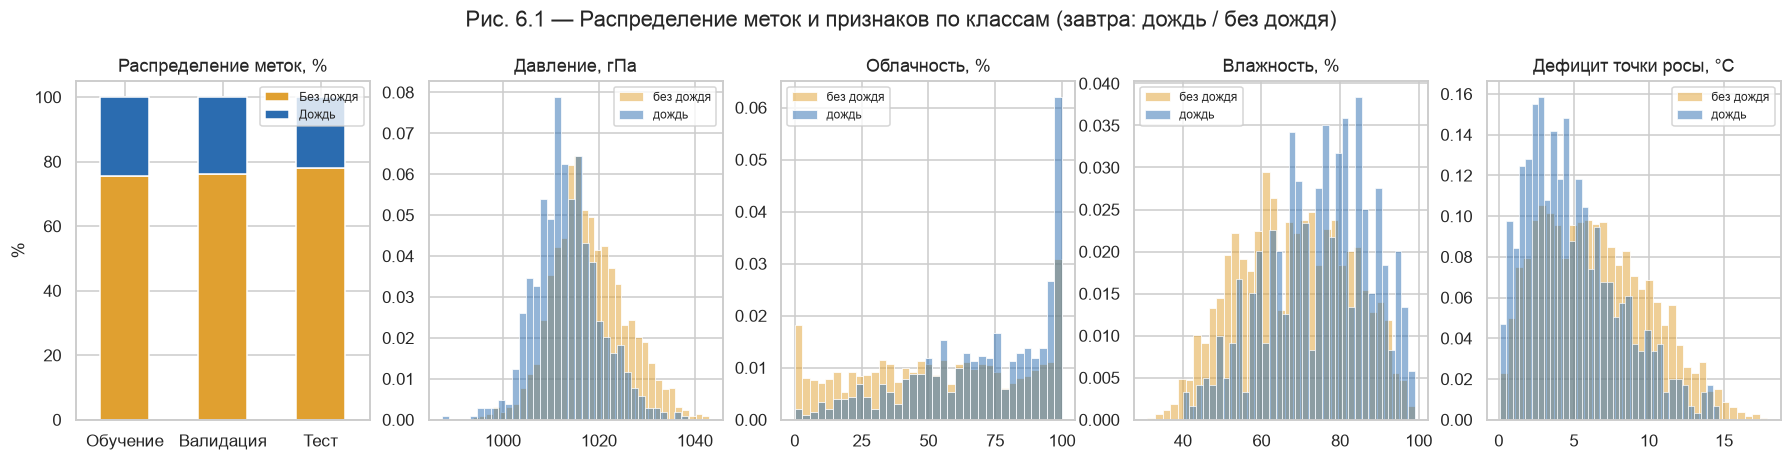

,Обучение,Валидация,Тест
Без дождя,75.6,76.2,77.9
Дождь,24.4,23.8,22.1


In [2]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
dist = pd.DataFrame({n: s[TARGET].value_counts().sort_index().values for n, s in
                     {"Обучение": train, "Валидация": valid, "Тест": test}.items()}, index=["Без дождя", "Дождь"])
(dist / dist.sum() * 100).T.plot(kind="bar", stacked=True, color=[C_DRY, C_WET], ax=axes[0], rot=0, legend=False)
axes[0].set(title="Распределение меток, %", ylabel="%"); axes[0].legend(fontsize=8)
for ax, f, name in zip(axes[1:], ["pressure_msl_mean", "cloud_cover_mean", "relative_humidity_2m_mean", "dew_point_depression"],
                       ["Давление, гПа", "Облачность, %", "Влажность, %", "Дефицит точки росы, °C"]):
    for cls, col, lab in [(0, C_DRY, "без дождя"), (1, C_WET, "дождь")]:
        sns.histplot(train.loc[y_tr == cls, f], ax=ax, color=col, stat="density", bins=35, alpha=0.5, label=lab)
    ax.set(title=name, xlabel="", ylabel=""); ax.legend(fontsize=8)
fig.suptitle("Рис. 6.1 — Распределение меток и признаков по классам (завтра: дождь / без дождя)", y=1.04)
save("fig_6_1_bias_distributions")
(dist / dist.sum() * 100).round(1)

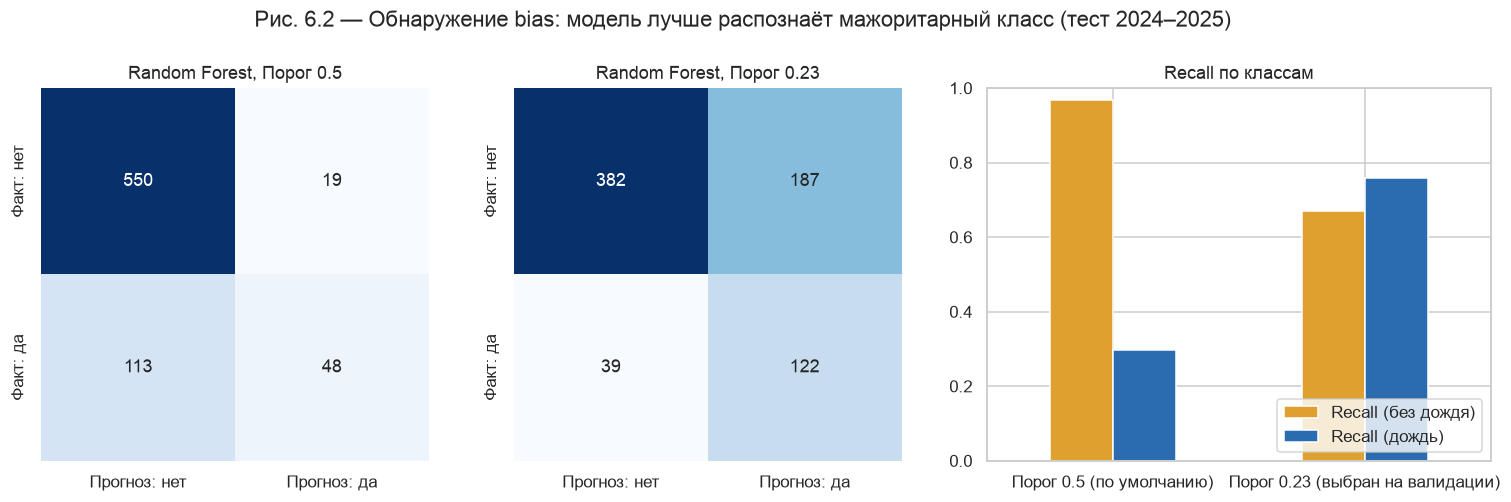

,Accuracy,Balanced acc.,Precision (дождь),Recall (дождь),F1 (дождь),Recall (без дождя),ROC-AUC,PR-AUC
Порог 0.5 (по умолчанию),0.819,0.632,0.716,0.298,0.421,0.967,0.793,0.551
Порог 0.23 (выбран на валидации),0.690,0.715,0.395,0.758,0.519,0.671,0.793,0.551


In [3]:
p_te = rf_base.predict_proba(X_te)[:, 1]
det = pd.DataFrame({"Порог 0.5 (по умолчанию)": class_metrics(y_te, (p_te >= 0.5).astype(int), p_te),
                    f"Порог {THR:.2f} (выбран на валидации)": class_metrics(y_te, (p_te >= THR).astype(int), p_te)}).T
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, (title, t) in zip(axes[:2], [("Порог 0.5", 0.5), (f"Порог {THR:.2f}", THR)]):
    cm = confusion_matrix(y_te, p_te >= t)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Прогноз: нет", "Прогноз: да"], yticklabels=["Факт: нет", "Факт: да"])
    ax.set_title(f"Random Forest, {title}")
det[["Recall (без дождя)", "Recall (дождь)"]].plot(kind="bar", ax=axes[2], color=[C_DRY, C_WET], rot=0)
axes[2].set(title="Recall по классам", ylim=(0, 1)); axes[2].legend(loc="lower right")
fig.suptitle("Рис. 6.2 — Обнаружение bias: модель лучше распознаёт мажоритарный класс (тест 2024–2025)", y=1.04)
save("fig_6_2_bias_detection")
det.round(3)

**Интерпретация.**
- **Bias классов в данных:** дни с дождём составляют лишь 22–24 % во всех выборках (дисбаланс ~1 : 3). Доля примерно одинакова в обучении, валидации и тесте — сдвига распределения между периодами нет.
- Распределения признаков классов сдвинуты (перед дождём ниже давление, выше облачность и влажность, меньше дефицит точки росы), но **сильно перекрываются** — модель не может разделить классы идеально.
- **Bias модели:** при стандартном пороге 0.5 Random Forest распознаёт **97 %** сухих дней, но лишь **30 %** дождливых. Accuracy при этом высокая (0.82) — она «прячет» bias, потому что хорошо угадывать мажоритарный класс легко. Balanced accuracy (0.63) показывает проблему честно.
- Порог, выбранный на валидации (0.23), уравновешивает классы: Recall дождя 0.76, сухих дней 0.67, balanced accuracy 0.72. Это первая мера коррекции, применённая в проекте (ноутбук 02).

## 1.2 Моделирование контролируемого bias классов

Как в лабораторной: начинаем с **сбалансированного** обучающего набора (дни «без дождя» случайно прорежены до числа дождливых дней), затем **намеренно удаляем 30 % и 70 %** дождливых дней и обучаем модели на искажённых данных.
В отличие от примера лабораторной (где тест делится из уже искажённых данных), тестовая выборка остаётся **неизменной и реальной** — иначе bias «прятался» бы и в оценке.

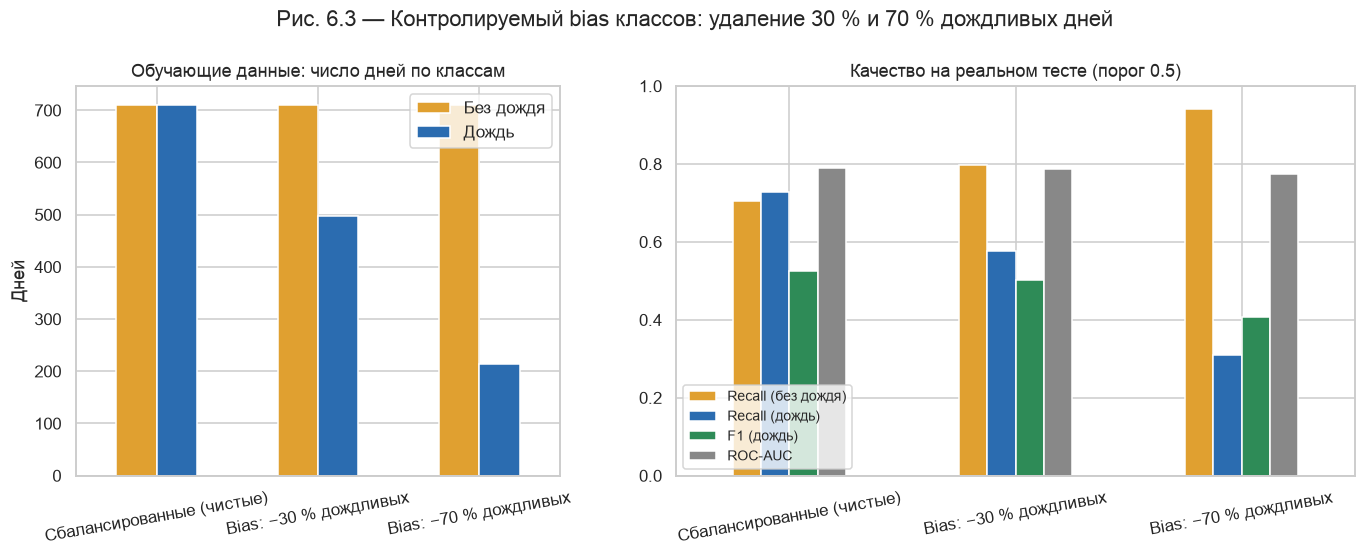

,Строк в обучении,"Доля дождя в обучении, %",Accuracy,Balanced acc.,Precision (дождь),Recall (дождь),F1 (дождь),Recall (без дождя),ROC-AUC,PR-AUC,Средняя вероятность
Сбалансированные (чистые),1422.0,50.000,0.710,0.716,0.411,0.727,0.525,0.705,0.788,0.506,0.443
Bias: −30 % дождливых,1209.0,41.191,0.748,0.687,0.445,0.578,0.503,0.796,0.788,0.503,0.373
Bias: −70 % дождливых,924.0,23.052,0.801,0.625,0.595,0.311,0.408,0.940,0.775,0.505,0.235


In [4]:
rain_tr, dry_tr = train[y_tr == 1], train[y_tr == 0]
balanced = pd.concat([rain_tr, dry_tr.sample(n=len(rain_tr), random_state=SEED)])

def introduce_bias(df, frac):
    # remove a share of the rainy days (class 1) — controlled class bias
    drop = df[df[TARGET] == 1].sample(frac=frac, random_state=SEED).index
    return df.drop(drop)

sets = {"Сбалансированные (чистые)": balanced, "Bias: −30 % дождливых": introduce_bias(balanced, 0.3),
        "Bias: −70 % дождливых": introduce_bias(balanced, 0.7)}
bias_rows, bias_models = {}, {}
for name, df in sets.items():
    m = new_rf().fit(df[FEATURES], df[TARGET])
    p = m.predict_proba(X_te)[:, 1]
    bias_models[name] = m
    bias_rows[name] = {"Строк в обучении": len(df), "Доля дождя в обучении, %": df[TARGET].mean() * 100,
                       **class_metrics(y_te, (p >= 0.5).astype(int), p), "Средняя вероятность": p.mean()}
bias_tbl = pd.DataFrame(bias_rows).T

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
pd.DataFrame({n: df[TARGET].value_counts().sort_index().values for n, df in sets.items()},
             index=["Без дождя", "Дождь"]).T.plot(kind="bar", color=[C_DRY, C_WET], ax=axes[0], rot=10)
axes[0].set(title="Обучающие данные: число дней по классам", ylabel="Дней")
bias_tbl[["Recall (без дождя)", "Recall (дождь)", "F1 (дождь)", "ROC-AUC"]].plot(kind="bar", ax=axes[1], rot=10,
                                                                                 color=[C_DRY, C_WET, "#2E8B57", "#888888"])
axes[1].set(title="Качество на реальном тесте (порог 0.5)", ylim=(0, 1)); axes[1].legend(fontsize=9, loc="lower left")
fig.suptitle("Рис. 6.3 — Контролируемый bias классов: удаление 30 % и 70 % дождливых дней", y=1.03)
save("fig_6_3_bias_simulation")
bias_tbl.round(3)

**Интерпретация.**
- На сбалансированных данных модель находит одинаково хорошо оба класса (Recall дождя 0.73, сухих дней 0.71).
- Удаление **30 %** дождливых дней снижает Recall дождя до 0.58, удаление **70 %** — до **0.31**, а Recall сухих дней растёт до 0.94: модель «учится», что дождь редок, и перестаёт его предсказывать.
- **Accuracy при этом растёт** (0.71 → 0.80) — ровно как в примере лабораторной: метрика выглядит лучше, а модель для предупреждений о дожде стала хуже. Balanced accuracy падает (0.72 → 0.63), F1 дождя — с 0.53 до 0.41.
- ROC-AUC почти не меняется (0.788 → 0.775): порядок дней по риску сохраняется, а **смещаются вероятности** (средняя вероятность дождя 0.44 → 0.24). Значит, bias классов в первую очередь искажает **калибровку и решение при фиксированном пороге**, а не саму способность различать.

## 1.3 Коррекция bias

Исправляем модель, обученную на данных с **−70 % дождливых дней**, тремя способами:
- **Resampling** (как в лабораторной): случайное дублирование дождливых дней до числа сухих (`sklearn.utils.resample`);
- **Reweighting**: веса классов обратно пропорциональны их частоте (`class_weight="balanced"`);
- **Сдвиг порога**: порог решения выбирается на валидационном 2023 году (данные валидации не искажены).

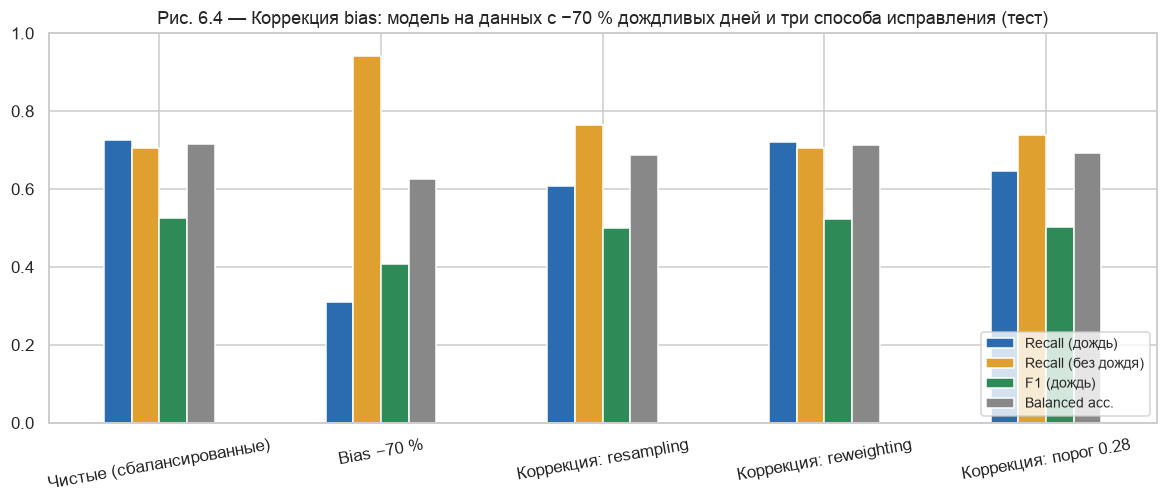

,Recall (дождь),Recall (без дождя),Precision (дождь),F1 (дождь),Balanced acc.,ROC-AUC,Средняя вероятность
Чистые (сбалансированные),0.727,0.705,0.411,0.525,0.716,0.788,0.443
Bias −70 %,0.311,0.940,0.595,0.408,0.625,0.775,0.235
Коррекция: resampling,0.609,0.764,0.422,0.499,0.687,0.772,0.373
Коррекция: reweighting,0.720,0.707,0.410,0.523,0.713,0.777,0.415
Коррекция: порог 0.28,0.646,0.738,0.411,0.502,0.692,0.775,0.235


In [5]:
biased = sets["Bias: −70 % дождливых"]

def correct_resample(df):
    major, minor = df[df[TARGET] == 0], df[df[TARGET] == 1]
    up = resample(minor, replace=True, n_samples=len(major), random_state=SEED)
    return pd.concat([major, up])

corr_rows = {}
corr_rows["Чистые (сбалансированные)"] = bias_rows["Сбалансированные (чистые)"]
corr_rows["Bias −70 %"] = bias_rows["Bias: −70 % дождливых"]
for name, fit in {
    "Коррекция: resampling": lambda: new_rf().fit(correct_resample(biased)[FEATURES], correct_resample(biased)[TARGET]),
    "Коррекция: reweighting": lambda: new_rf(class_weight="balanced").fit(biased[FEATURES], biased[TARGET]),
}.items():
    m = fit(); p = m.predict_proba(X_te)[:, 1]
    corr_rows[name] = {**class_metrics(y_te, (p >= 0.5).astype(int), p), "Средняя вероятность": p.mean()}
m = bias_models["Bias: −70 % дождливых"]
t = tune_threshold(y_va, m.predict_proba(X_va)[:, 1]); p = m.predict_proba(X_te)[:, 1]
corr_rows[f"Коррекция: порог {t:.2f}"] = {**class_metrics(y_te, (p >= t).astype(int), p), "Средняя вероятность": p.mean()}
corr_tbl = pd.DataFrame(corr_rows).T[["Recall (дождь)", "Recall (без дождя)", "Precision (дождь)", "F1 (дождь)",
                                      "Balanced acc.", "ROC-AUC", "Средняя вероятность"]]
fig, ax = plt.subplots(figsize=(13, 4.6))
corr_tbl[["Recall (дождь)", "Recall (без дождя)", "F1 (дождь)", "Balanced acc."]].plot(kind="bar", ax=ax, rot=10,
                                                                                      color=[C_WET, C_DRY, "#2E8B57", "#888888"])
ax.set(ylim=(0, 1), title="Рис. 6.4 — Коррекция bias: модель на данных с −70 % дождливых дней и три способа исправления (тест)")
ax.legend(loc="lower right", fontsize=9)
save("fig_6_4_bias_correction")
corr_tbl.round(3)

**Интерпретация.**
- **Reweighting** (`class_weight="balanced"`) восстанавливает модель почти полностью: Recall дождя 0.31 → 0.72, F1 0.41 → 0.52, balanced accuracy 0.63 → 0.71 — практически уровень модели на чистых сбалансированных данных.
- **Resampling** (дублирование дождливых дней, как в лабораторной) помогает частично (Recall 0.61, F1 0.50): копии одних и тех же 213 дней дают модели мало новой информации, и деревья подстраиваются под них.
- **Сдвиг порога** (0.28 по валидации) тоже восстанавливает Recall (0.65) без переобучения модели — самый дешёвый способ, но требует неискажённых валидационных данных.
- В отличие от примера лабораторной, где точность «исправленной» модели выросла до 0.95, у нас тест не содержит дублированных строк — поэтому коррекция честно возвращает качество к уровню чистых данных, но не выше.

## 1.4 Bias на признаках

Bias бывает не только в метках, но и в **признаках**. Моделируем систематическую ошибку датчика, связанную с классом: в обучающих данных облачность перед дождливыми днями записана **заниженной на 40 %** (`cloud_cover_mean × 0.6` для класса «дождь») — например, если датчик облачности плохо работает в пасмурную погоду.
Модель обучается на искажённых данных и проверяется на реальном тесте. Сравниваем способы коррекции:
- **нормализация** (`StandardScaler`, предложена в примере лабораторной);
- **исключение искажённого признака**;
- **перекалибровка признака** по доверенному эталону: коэффициент искажения оценивается сравнением распределения признака в обучающих данных с неискажённым эталонным периодом (валидация 2023).

Истинный коэффициент искажения 0.6, оценённый по эталону: 0.623


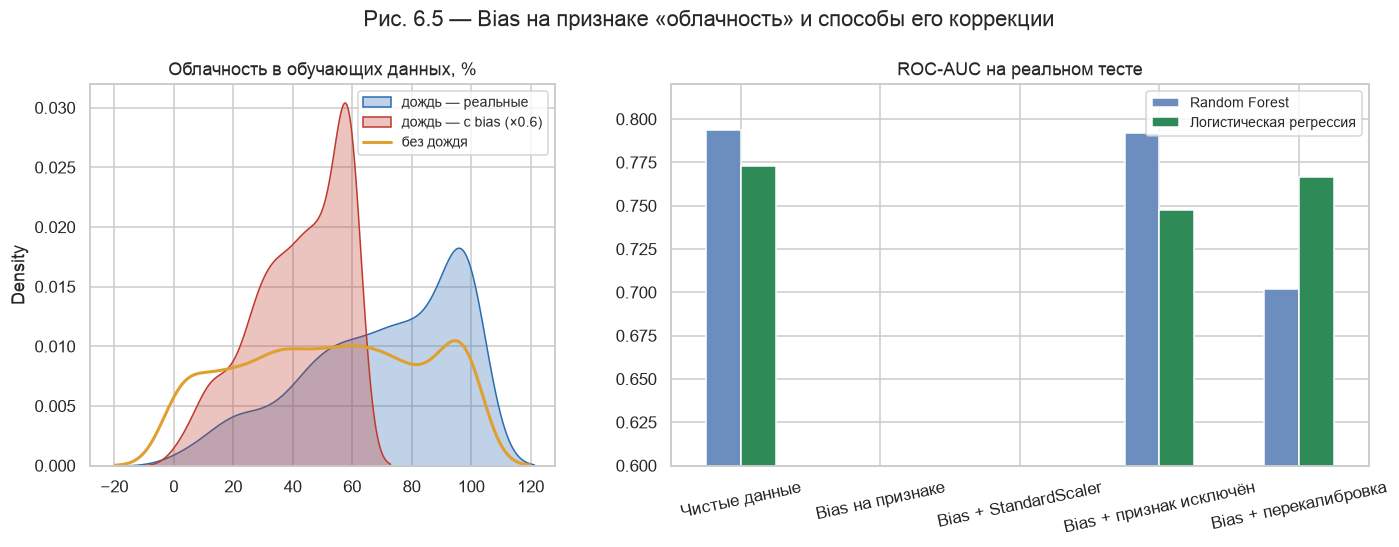

ROC-AUC  F1 (дождь)  \
Random Forest           Чистые данные              0.793       0.519   
                        Bias на признаке           0.431       0.170   
                        Bias + StandardScaler      0.431       0.170   
                        Bias + признак исключён    0.792       0.536   
                        Bias + перекалибровка      0.702       0.431   
Логистическая регрессия Чистые данные              0.773       0.524   
                        Bias на признаке           0.521       0.326   
                        Bias + StandardScaler      0.521       0.326   
                        Bias + признак исключён    0.747       0.451   
                        Bias + перекалибровка      0.767       0.501   

                                                 Recall (дождь)  \
Random Forest           Чистые данные                     0.758   
                        Bias на признаке                  0.236   
                        Bias + StandardScaler             0.236   
                        Bias + признак исключён           0.783   
                        Bias + перекалибровка             0.727   
Логистическая регрессия Чистые данные                     0.776   
                        Bias на признаке                  0.590   
                        Bias + StandardScaler             0.590   
                        Bias + признак исключён           0.752   
                        Bias + перекалибровка             0.752   

                                                 Средняя вероятность  
Random Forest           Чистые данные                          0.237  
                        Bias на признаке                       0.111  
                        Bias + StandardScaler                  0.111  
                        Bias + признак исключён                0.237  
                        Bias + перекалибровка                  0.209  
Логистическая регрессия Чистые данные                          0.232  
                        Bias на признаке                       0.174  
                        Bias + StandardScaler                  0.174  
                        Bias + признак исключён                0.234  
                        Bias + перекалибровка                  0.234

In [6]:
FACTOR, BF = 0.6, "cloud_cover_mean"
X_bias = X_tr.copy()
X_bias.loc[y_tr == 1, BF] = X_bias.loc[y_tr == 1, BF] * FACTOR

# recalibration: estimate the distortion factor from a trusted reference period (2023 is undistorted)
est_factor = X_bias.loc[y_tr == 1, BF].mean() / X_va.loc[y_va == 1, BF].mean()
X_recal = X_bias.copy(); X_recal.loc[y_tr == 1, BF] = X_recal.loc[y_tr == 1, BF] / est_factor
print(f"Истинный коэффициент искажения {FACTOR}, оценённый по эталону: {est_factor:.3f}")

FEATS_NO_BF = [f for f in FEATURES if f != BF]
scen = {
    "Чистые данные": (X_tr, FEATURES, None),
    "Bias на признаке": (X_bias, FEATURES, None),
    "Bias + StandardScaler": (X_bias, FEATURES, "scale"),
    "Bias + признак исключён": (X_bias, FEATS_NO_BF, None),
    "Bias + перекалибровка": (X_recal, FEATURES, None),
}
fb_rows = {}
for model_name, base in {"Random Forest": new_rf(), "Логистическая регрессия": LogisticRegression(C=0.1, max_iter=5000)}.items():
    for name, (X, cols, prep) in scen.items():
        m = make_pipeline(StandardScaler(), clone(base)) if (prep == "scale" or model_name != "Random Forest") else clone(base)
        m.fit(X[cols], y_tr)
        t = tune_threshold(y_va, m.predict_proba(X_va[cols])[:, 1]); p = m.predict_proba(X_te[cols])[:, 1]
        fb_rows[(model_name, name)] = {"ROC-AUC": roc_auc_score(y_te, p), "F1 (дождь)": f1_score(y_te, p >= t),
                                       "Recall (дождь)": recall_score(y_te, p >= t), "Средняя вероятность": p.mean()}
fb_tbl = pd.DataFrame(fb_rows).T

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
sns.kdeplot(X_tr.loc[y_tr == 1, BF], ax=a1, color=C_WET, label="дождь — реальные", fill=True, alpha=0.3)
sns.kdeplot(X_bias.loc[y_tr == 1, BF], ax=a1, color="#C0392B", label="дождь — с bias (×0.6)", fill=True, alpha=0.3)
sns.kdeplot(X_tr.loc[y_tr == 0, BF], ax=a1, color=C_DRY, label="без дождя", lw=2)
a1.set(title="Облачность в обучающих данных, %", xlabel=""); a1.legend(fontsize=9)
fb_tbl["ROC-AUC"].unstack(0).loc[list(scen)].plot(kind="bar", ax=a2, rot=12, color=["#6C8EBF", "#2E8B57"])
a2.set(ylim=(0.6, 0.82), title="ROC-AUC на реальном тесте"); a2.legend(fontsize=9)
fig.suptitle("Рис. 6.5 — Bias на признаке «облачность» и способы его коррекции", y=1.03)
save("fig_6_5_feature_bias")
fb_tbl.round(3)

**Интерпретация.**
- **Bias на признаке разрушителен:** заниженная перед дождём облачность «учит» модель обратной связи (меньше облаков → дождь). На реальном тесте Random Forest падает до ROC-AUC **0.43 — хуже случайного угадывания**, Recall дождя 0.24; логистическая регрессия — до 0.52.
- **Нормализация (`StandardScaler`), предложенная в примере лабораторной, не помогает вообще** (метрики идентичны): масштабирование меняет единицы признака, но не связь «признак ↔ класс». Для деревьев решений масштаб и вовсе не важен. Это важный вывод: bias, зависящий от класса, нормализацией не исправляется.
- **Исключение искажённого признака** полностью восстанавливает Random Forest (ROC-AUC 0.79): информацию об облачности частично несут другие признаки (вчерашняя облачность, доля солнечного сияния, влажность).
- **Перекалибровка по эталону** (коэффициент оценён по неискажённому 2023 году: 0.62 при истинном 0.6) лучше всего работает для логистической регрессии (0.77 из 0.77) и частично для Random Forest (0.70): деление на средний коэффициент восстанавливает среднее, но не точные значения, а дерево чувствительно к порогам.

## 1.5 Ответы на вопросы лабораторной (Bias)

**Какой тип bias вы наблюдали в исходных данных?**
В первую очередь **bias классов** (дни с дождём — 24 %), из-за которого модель при стандартном пороге смещена к мажоритарному классу (Recall 0.97 для сухих дней против 0.30 для дождливых). В ноутбуке 03 обнаружены также **bias выборки** (модель, обученная только на тёплом сезоне, завышает вероятность дождя зимой), **региональный bias калибровки** (на юге вероятность дождя слегка завышена) и **bias измерений** (недоучёт осадкомера).

**Как bias повлиял на качество модели?**
При удалении 70 % дождливых дней Recall дождя упал с 0.73 до 0.31, F1 — с 0.53 до 0.41, balanced accuracy — с 0.72 до 0.63, а accuracy *выросла* с 0.71 до 0.80. Bias на признаке «облачность» опустил ROC-AUC Random Forest до 0.43. Bias сильнее всего бьёт по редкому, но самому важному классу и маскируется «хорошей» accuracy.

**Чем отличаются модель с bias и исправленная модель?**
Исправленная перевзвешиванием модель находит 72 % дождливых дней вместо 31 % и возвращает F1 и balanced accuracy к уровню чистых данных; её вероятности снова близки к реальной частоте. Цена — больше ложных тревог (Recall сухих дней 0.94 → 0.71). При bias на признаке исправленная модель (без признака или с перекалибровкой) снова опирается на правильную физическую связь «больше облаков → дождь».

**Какие альтернативные методы коррекции можно исследовать?**
SMOTE / ADASYN (раздел 4), прореживание мажоритарного класса, Balanced Random Forest, обучение с матрицей стоимости ошибок, калибровку вероятностей (Platt, изотоническая), отдельные пороги для регионов и сезонов, сбор данных с недопредставленных станций и сезонов, ограничения справедливости (одинаковый Recall для всех регионов), сверку датчиков с соседними станциями (реализовано в ноутбуке 04).

**Как эта проблема связана со справедливостью и ответственностью в ИИ?**
Модель с bias «не видит» редкие, но важные ситуации — дождливые дни, южные районы, зиму. Если по её прогнозам принимаются решения (полевые работы, мероприятия, экстренные службы), то цена ошибок ложится на тех, кого модель не видит. Accuracy создаёт иллюзию качества, поэтому ответственный специалист обязан показывать метрики **по классам и по группам** (сезоны, регионы). Как отмечено в материалах курса, *мораль* здесь — ценность защиты людей от непогоды, а *этика* — осознанный выбор того, какие ошибки (пропуски или ложные тревоги) мы готовы допускать и кому их цена достанется.

---
# 2. NOISE — «дождь на стекле обучения»

**Определение.** Noise (шум) — случайные колебания, ошибки или нерелевантная информация, мешающие модели учиться.
В метеоданных шум — это погрешности датчиков, ошибки передачи, выбросы.

## 2.1 Классификация: модели под гауссовым шумом разной силы

Как в лабораторной (проект №19): четыре модели — логистическая регрессия, KNN (k = 5), Random Forest, SVC — в режимах **без шума** и **с гауссовым шумом** со стандартным отклонением σ = 0.2, 0.5 и 1.0. Шум добавляется к **стандартизованным** признакам (в единицах их стандартного отклонения) во всех выборках — так моделируется зашумлённый архив станции. Порог решения выбирается на (тоже зашумлённой) валидации.

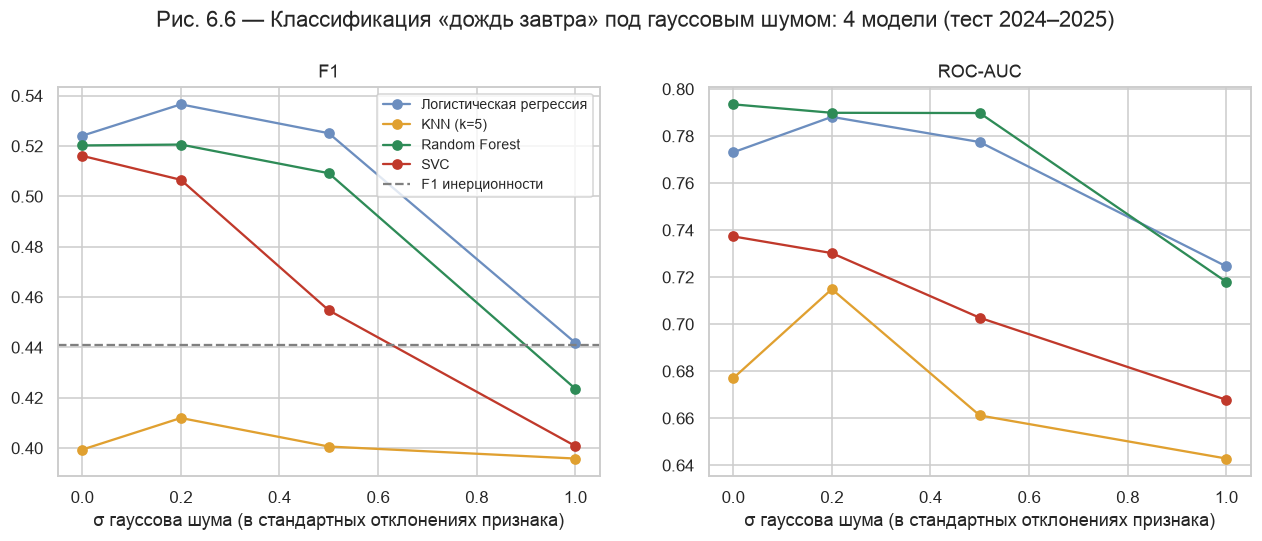

,Модель,Noise STD,Accuracy,Precision,Recall,F1,ROC-AUC
0,Логистическая регрессия,0.0,0.6890,0.3956,0.7764,0.5241,0.7731
1,KNN (k=5),0.0,0.4726,0.2667,0.7950,0.3994,0.6770
2,Random Forest,0.0,0.6918,0.3961,0.7578,0.5203,0.7935
3,SVC,0.0,0.7329,0.4298,0.6460,0.5161,0.7373
4,Логистическая регрессия,0.2,0.7137,0.4172,0.7516,0.5366,0.7882
5,KNN (k=5),0.2,0.4877,0.2758,0.8137,0.4119,0.7149
6,Random Forest,0.2,0.6973,0.4000,0.7453,0.5206,0.7899
7,SVC,0.2,0.7438,0.4404,0.5963,0.5066,0.7302
8,Логистическая регрессия,0.5,0.7151,0.4152,0.7143,0.5251,0.7775
9,KNN (k=5),0.5,0.4589,0.2651,0.8199,0.4006,0.6612


In [7]:
sc = StandardScaler().fit(X_tr)
Z_tr, Z_va, Z_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
clf_models = {
    "Логистическая регрессия": LogisticRegression(C=0.1, max_iter=5000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": new_rf(),
    "SVC": SVC(probability=True, random_state=SEED),
}
NOISE_STD = [0.0, 0.2, 0.5, 1.0]
rng = np.random.default_rng(SEED)
noise_rows = []
for s in NOISE_STD:
    nz = lambda Z: Z + rng.normal(0, s, Z.shape) if s > 0 else Z
    Ztr, Zva, Zte = nz(Z_tr), nz(Z_va), nz(Z_te)
    for name, base in clf_models.items():
        m = clone(base).fit(Ztr, y_tr)
        t = tune_threshold(y_va, m.predict_proba(Zva)[:, 1]); p = m.predict_proba(Zte)[:, 1]; pred = (p >= t).astype(int)
        noise_rows.append({"Модель": name, "Noise STD": s, "Accuracy": accuracy_score(y_te, pred),
                           "Precision": precision_score(y_te, pred, zero_division=0), "Recall": recall_score(y_te, pred),
                           "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, p)})
noise_tbl = pd.DataFrame(noise_rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, metric in zip(axes, ["F1", "ROC-AUC"]):
    for (name, g), col in zip(noise_tbl.groupby("Модель", sort=False), ["#6C8EBF", "#E0A030", "#2E8B57", "#C0392B"]):
        ax.plot(g["Noise STD"], g[metric], "o-", color=col, label=name)
    ax.set(xlabel="σ гауссова шума (в стандартных отклонениях признака)", title=metric)
axes[0].axhline(0.441, ls="--", color="gray", label="F1 инерционности"); axes[0].legend(fontsize=9)
fig.suptitle("Рис. 6.6 — Классификация «дождь завтра» под гауссовым шумом: 4 модели (тест 2024–2025)", y=1.03)
save("fig_6_6_noise_classification")
noise_tbl.round(4)

**Интерпретация.**
- **Без шума** лучшие модели — Random Forest (ROC-AUC 0.79) и логистическая регрессия (0.77); KNN (k = 5) заметно слабее (0.68): в 26-мерном пространстве ближайшие 5 соседей случайны — «проклятие размерности».
- **Слабый шум (σ = 0.2)** не вредит и даже немного улучшает логистическую регрессию (0.773 → 0.788) и KNN: небольшой шум в обучающих данных действует как **регуляризация** (аугментация данных).
- **При σ = 0.5** Random Forest практически не теряет (0.790), логистическая регрессия теряет немного (0.778), SVC — заметно (0.737 → 0.703).
- **При σ = 1.0** (шум равен разбросу самого признака) все модели деградируют: ROC-AUC 0.64–0.72, F1 0.40–0.44 — **ниже инерционности** (0.44).
- **Самая устойчивая модель — Random Forest** (усреднение сотен деревьев сглаживает шум), самая чувствительная — KNN (решение по нескольким соседям, которых шум «перемешивает»). Это совпадает с выводами лабораторной для синтетических данных.

## 2.2 Регрессия: прогноз максимальной температуры завтра под шумом

Как в лабораторной (проект №21, метрики MSE, R², MAE и модели Linear Regression, KNN, Random Forest, SVR) — для непрерывной величины нашей задачи: **максимальной температуры завтра**. Базовая линия — «завтра как сегодня» (T_max сегодня).

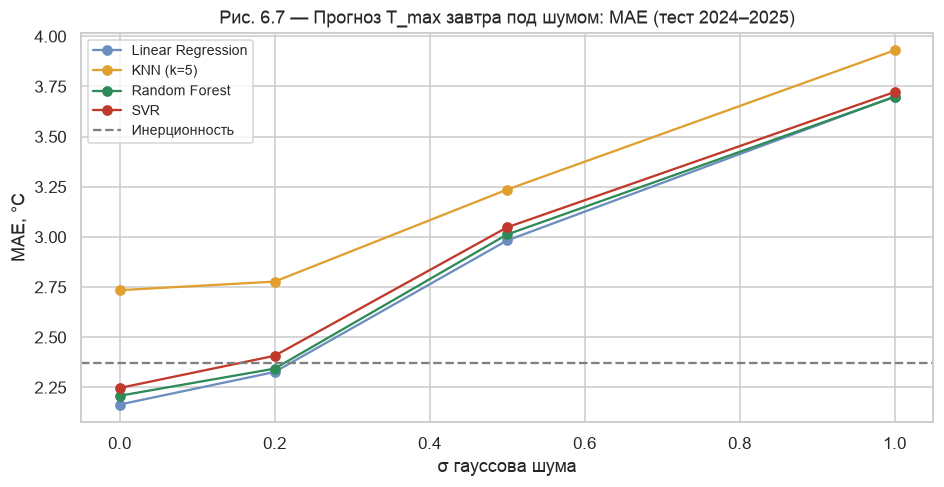

,Модель,Noise STD,MSE,R²,MAE
0,Инерционность (T_max сегодня),0.0,9.3759,0.9052,2.3714
1,Linear Regression,0.0,7.5689,0.9234,2.1646
2,KNN (k=5),0.0,11.9799,0.8788,2.7347
3,Random Forest,0.0,7.7169,0.9219,2.2083
4,SVR,0.0,8.5219,0.9138,2.2471
5,Linear Regression,0.2,8.7160,0.9118,2.3268
6,KNN (k=5),0.2,12.4752,0.8738,2.7774
7,Random Forest,0.2,8.5568,0.9134,2.3436
8,SVR,0.2,9.6955,0.9019,2.4076
9,Linear Regression,0.5,14.0842,0.8575,2.9825


In [8]:
tmax = daily.set_index("date").temperature_2m_max
yr_tr, yr_va, yr_te = (train.date.map(tmax.shift(-1)).values, valid.date.map(tmax.shift(-1)).values,
                       test.date.map(tmax.shift(-1)).values)
persist = test.date.map(tmax).values
reg_models = {
    "Linear Regression": LinearRegression(),
    "KNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1),
    "SVR": SVR(C=10),
}
rng = np.random.default_rng(SEED)
reg_rows = [{"Модель": "Инерционность (T_max сегодня)", "Noise STD": 0.0, "MSE": mean_squared_error(yr_te, persist),
             "R²": r2_score(yr_te, persist), "MAE": mean_absolute_error(yr_te, persist)}]
for s in NOISE_STD:
    nz = lambda Z: Z + rng.normal(0, s, Z.shape) if s > 0 else Z
    Ztr, Zte = nz(Z_tr), nz(Z_te)
    for name, base in reg_models.items():
        pr = clone(base).fit(Ztr, yr_tr).predict(Zte)
        reg_rows.append({"Модель": name, "Noise STD": s, "MSE": mean_squared_error(yr_te, pr),
                         "R²": r2_score(yr_te, pr), "MAE": mean_absolute_error(yr_te, pr)})
reg_tbl = pd.DataFrame(reg_rows)
fig, ax = plt.subplots(figsize=(10, 4.6))
for (name, g), col in zip(reg_tbl[reg_tbl["Модель"] != "Инерционность (T_max сегодня)"].groupby("Модель", sort=False),
                          ["#6C8EBF", "#E0A030", "#2E8B57", "#C0392B"]):
    ax.plot(g["Noise STD"], g["MAE"], "o-", color=col, label=name)
ax.axhline(reg_tbl.iloc[0]["MAE"], ls="--", color="gray", label="Инерционность")
ax.set(xlabel="σ гауссова шума", ylabel="MAE, °C", title="Рис. 6.7 — Прогноз T_max завтра под шумом: MAE (тест 2024–2025)")
ax.legend(fontsize=9)
save("fig_6_7_noise_regression")
reg_tbl.round(4)

**Интерпретация.**
- Без шума все модели лучше инерционности (MAE 2.37 °C): лучшие — линейная регрессия (MAE **2.16 °C**, R² 0.92) и Random Forest (2.21 °C). Температура завтра почти линейно зависит от сегодняшней, поэтому простая модель здесь не уступает сложной.
- Уже при σ = 0.2 преимущество над инерционностью почти исчезает (MAE 2.33–2.41), а при σ = 0.5 **все модели хуже наивного прогноза** (MAE ≈ 3.0 °C): шум «съедает» именно ту точность, которую дают модели.
- KNN снова самая чувствительная модель (MAE 2.73 уже без шума, R² 0.88).
- Вывод: для регрессии требования к точности датчиков ещё строже, чем для классификации — нужна фильтрация шума (раздел 2.3) или более точные приборы.

## 2.3 Denoising — снижение влияния шума

Шум датчиков в реальном времени можно **отфильтровать до** вычисления признаков. Используем только **каузальные** фильтры (по текущему и прошлым дням — в реальном времени будущее неизвестно):
- **скользящая медиана** за 3 дня;
- **экспоненциальное сглаживание** (EWMA, α = 0.5);
- **фильтр Хампеля** (окно 5 дней): значение, отклоняющееся от медианы окна более чем на 3 MAD, заменяется медианой — предназначен для **выбросов**.

Два типа шума на сырых показаниях датчиков тестового периода: **гауссов** (σ = 0.3 и 0.5 стандартного отклонения величины) и **импульсный** (5 % показаний заменены выбросами ±6σ — сбои передачи).
Оцениваем (1) насколько фильтр приближает сигнал к истинному (нормированная MSE, как MSE в задаче denoising изображений) и (2) качество модели Random Forest (обучена на чистых данных).
Оценка всегда по истинным меткам.

In [9]:
SENSOR_COLS = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "dew_point_2m_mean",
               "relative_humidity_2m_mean", "relative_humidity_2m_max", "pressure_msl_mean", "pressure_msl_max",
               "pressure_msl_min", "cloud_cover_mean", "wind_speed_10m_max", "soil_moisture_0_to_7cm_mean",
               "vapour_pressure_deficit_max", "sunshine_duration"]
raw = daily.copy()
period = (raw.date >= test.date.min() - pd.Timedelta(days=14)).values
sig_std = raw.loc[raw.date.dt.year <= 2022, SENSOR_COLS].std()

def corrupt(kind, level, seed=SEED):
    r = raw.copy(); rng = np.random.default_rng(seed)
    block = r.loc[period, SENSOR_COLS].values
    if kind == "gauss":
        block = block + rng.normal(0, 1, block.shape) * (level * sig_std.values)
    else:  # impulse: a share of readings replaced by +-6 sigma spikes
        mask = rng.random(block.shape) < level
        block = np.where(mask, block + rng.choice([-6, 6], block.shape) * sig_std.values, block)
    r.loc[period, SENSOR_COLS] = block
    for c in ["relative_humidity_2m_mean", "relative_humidity_2m_max", "cloud_cover_mean"]:
        r[c] = r[c].clip(0, 100)
    for c in ["wind_speed_10m_max", "soil_moisture_0_to_7cm_mean", "vapour_pressure_deficit_max"]:
        r[c] = r[c].clip(lower=0)
    r["sunshine_duration"] = r["sunshine_duration"].clip(0, r["daylight_duration"])
    return r

def hampel(s, window=5, k=3.0):
    med = s.rolling(window, min_periods=1).median()
    mad = (s - med).abs().rolling(window, min_periods=1).median() * 1.4826
    return s.where((s - med).abs() <= k * mad.replace(0, np.inf), med)

FILTERS = {
    "Без фильтра": lambda s: s,
    "Медиана 3 дня": lambda s: s.rolling(3, min_periods=1).median(),
    "EWMA α=0.5": lambda s: s.ewm(alpha=0.5, adjust=False).mean(),
    "Хампель": hampel,
}
def denoise(r, flt):
    r = r.copy()
    for c in SENSOR_COLS:
        r[c] = FILTERS[flt](r[c])
    return r

def evaluate(r):
    t = test[["date", TARGET]].merge(compute_features(r), on="date")
    p = rf_base.predict_proba(t[FEATURES])[:, 1]
    return roc_auc_score(t[TARGET], p), f1_score(t[TARGET], p >= THR)

def signal_nmse(r):
    a = r.loc[period, SENSOR_COLS]; b = raw.loc[period, SENSOR_COLS]
    return float((((a - b) ** 2).mean() / sig_std ** 2).mean())

dn_rows = []
for noise_name, kind, level in [("Без шума", "gauss", 0.0), ("Гауссов σ=0.3", "gauss", 0.3), ("Гауссов σ=0.5", "gauss", 0.5),
                                ("Импульсный 5 %", "impulse", 0.05)]:
    noisy = corrupt(kind, level)
    for flt in FILTERS:
        r = denoise(noisy, flt)
        auc, f1 = evaluate(r)
        dn_rows.append({"Шум": noise_name, "Фильтр": flt, "NMSE сигнала": signal_nmse(r), "ROC-AUC": auc, "F1": f1})
dn_tbl = pd.DataFrame(dn_rows).set_index(["Шум", "Фильтр"])
dn_tbl.round(4)

NMSE сигнала  ROC-AUC      F1
Шум            Фильтр                                      
Без шума       Без фильтра          0.0000   0.7935  0.5191
               Медиана 3 дня        0.2334   0.7717  0.4736
               EWMA α=0.5           0.0974   0.7863  0.5256
               Хампель              0.0862   0.7887  0.5118
Гауссов σ=0.3  Без фильтра          0.0868   0.7610  0.4880
               Медиана 3 дня        0.2679   0.7601  0.4789
               EWMA α=0.5           0.1273   0.7708  0.5149
               Хампель              0.1540   0.7610  0.4911
Гауссов σ=0.5  Без фильтра          0.2365   0.7449  0.4695
               Медиана 3 дня        0.3323   0.7534  0.4767
               EWMA α=0.5           0.1788   0.7589  0.4990
               Хампель              0.2776   0.7468  0.4729
Импульсный 5 % Без фильтра          1.3740   0.7819  0.5051
               Медиана 3 дня        0.3681   0.7677  0.4740
               EWMA α=0.5           0.5622   0.7646  0.4970
               Хампель              0.2727   0.7821  0.5180

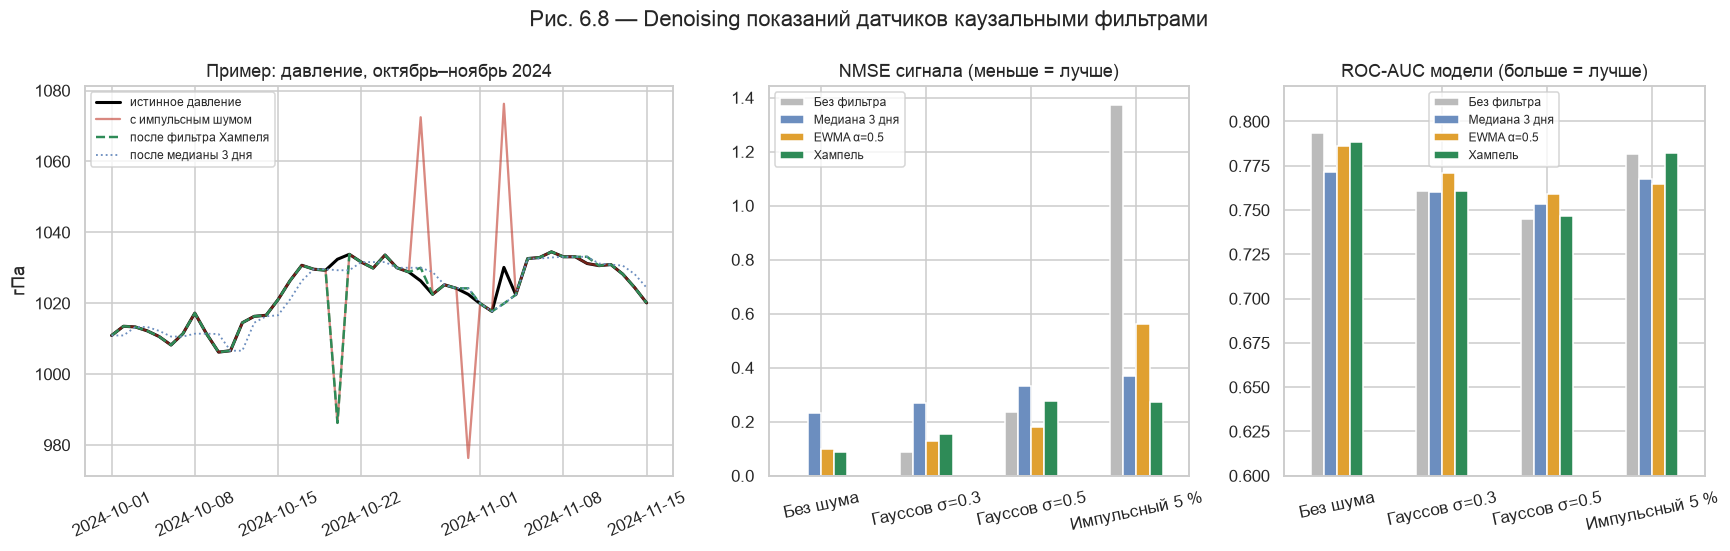

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
w = (raw.date >= "2024-10-01") & (raw.date <= "2024-11-15")
noisy_g = corrupt("gauss", 0.5); noisy_i = corrupt("impulse", 0.05)
axes[0].plot(raw.date[w], raw.pressure_msl_mean[w], color="black", lw=2, label="истинное давление")
axes[0].plot(raw.date[w], noisy_i.pressure_msl_mean[w], color="#C0392B", alpha=0.6, label="с импульсным шумом")
axes[0].plot(raw.date[w], denoise(noisy_i, "Хампель").pressure_msl_mean[w], color="#2E8B57", lw=1.6, ls="--", label="после фильтра Хампеля")
axes[0].plot(raw.date[w], denoise(noisy_i, "Медиана 3 дня").pressure_msl_mean[w], color="#6C8EBF", lw=1.2, ls=":", label="после медианы 3 дня")
axes[0].set(title="Пример: давление, октябрь–ноябрь 2024", ylabel="гПа"); axes[0].legend(fontsize=8); axes[0].tick_params(axis="x", rotation=25)
for ax, metric in zip(axes[1:], ["NMSE сигнала", "ROC-AUC"]):
    dn_tbl[metric].unstack(1)[list(FILTERS)].loc[["Без шума", "Гауссов σ=0.3", "Гауссов σ=0.5", "Импульсный 5 %"]].plot(
        kind="bar", ax=ax, rot=12, color=["#BBBBBB", "#6C8EBF", "#E0A030", "#2E8B57"])
    ax.set(title=metric + (" (меньше = лучше)" if "NMSE" in metric else " модели (больше = лучше)"), xlabel="")
    ax.legend(fontsize=8)
axes[2].set_ylim(0.6, 0.82)
fig.suptitle("Рис. 6.8 — Denoising показаний датчиков каузальными фильтрами", y=1.03)
save("fig_6_8_denoising")

**Интерпретация.**
- **Фильтры полезны только против «своего» типа шума:**
  - против **гауссова** шума лучше всего **EWMA**: ROC-AUC 0.761 → 0.771 и F1 0.488 → 0.515 при σ = 0.3; 0.745 → 0.759 и 0.470 → 0.499 при σ = 0.5;
  - против **импульсного** шума (выбросы) лучше всего **фильтр Хампеля**: ошибка сигнала падает в 5 раз (NMSE 1.37 → 0.27), F1 0.505 → 0.518; медиана тоже убирает выбросы (NMSE 0.37), но сильнее искажает нормальные значения.
- **На чистых данных любой фильтр немного вредит** (медиана 3 дня: ROC-AUC 0.794 → 0.772): суточная погода меняется быстро, и сглаживание стирает реальные изменения (например, резкое падение давления перед фронтом). Поэтому EWMA при слабом гауссовом шуме даже увеличивает ошибку сигнала (NMSE 0.087 → 0.127), хотя качество модели растёт — модель выигрывает от более гладких трендов, а не от более точных значений.
- На примере (рис. 6.8, слева) видно, что каузальный фильтр Хампеля не идеален: один выброс (около 20.10) он пропустил, а реальный пик давления 3.11 «срезал» — фильтр видит только прошлые дни и не может отличить начало резкого реального изменения от сбоя.
- Random Forest сам по себе устойчив к редким выбросам (ROC-AUC 0.782 с импульсным шумом без фильтра).
- **Принятая мера:** denoising выполняется **не всегда, а по сигналу контроля качества**: фильтр Хампеля — при обнаружении выбросов, EWMA — при повышенном шуме датчика; на исправных датчиках данные не фильтруются.

## 2.4 Наблюдения по Noise (вопросы лабораторной «Что можно наблюдать?»)

1. **Чувствительность к шуму различна:** линейные модели (логистическая и линейная регрессия) упрощают зависимость и деградируют плавно; KNN хорошо работает только при малой размерности и сильно страдает от шума; Random Forest — самый устойчивый.
2. **Ошибки растут вместе с шумом:** MAE прогноза температуры 2.16 → 3.70 °C, ROC-AUC прогноза дождя 0.79 → 0.72 при σ = 1 — количественный индикатор влияния шума.
3. **Малый шум может быть полезен:** при σ = 0.2 логистическая регрессия и KNN немного улучшились — шум в обучении работает как регуляризация. «Шум защищает» и в смысле материалов курса: контролируемый шум позволяет делиться данными, скрывая точные значения, без потери аналитической ценности (при σ ≤ 0.2 качество почти не меняется).
4. **Denoising — не универсальное лекарство:** фильтр подбирается под тип шума и включается только при обнаружении проблемы; на чистых данных он вредит.
5. **Связь с bias / variance:** простые модели (высокий bias) устойчивее к шуму, гибкие (высокая variance — KNN, глубокие деревья) «учат» шум — это мост к разделу 3.

---
# 3. UNDERFITTING и OVERFITTING — «поэзия равновесия»

- **Underfitting:** модель слишком проста, не улавливает структуру данных и плохо обобщает (низкое качество и на обучении, и на новых данных).
- **Overfitting:** модель слишком сложна, **запоминает шум** обучающих данных: почти идеальна на обучении, но хуже на новых данных (большой разрыв между обучением и проверкой).

## 3.1 Кривые сложности (validation curves)

Меняем сложность трёх моделей и сравниваем ROC-AUC на **обучении** и на **валидации 2023**:
- Random Forest — максимальная глубина деревьев (листья до 1 примера, без регуляризации);
- KNN — число соседей k (малое k = сложная модель);
- логистическая регрессия — сила регуляризации C (большое C = слабая регуляризация).

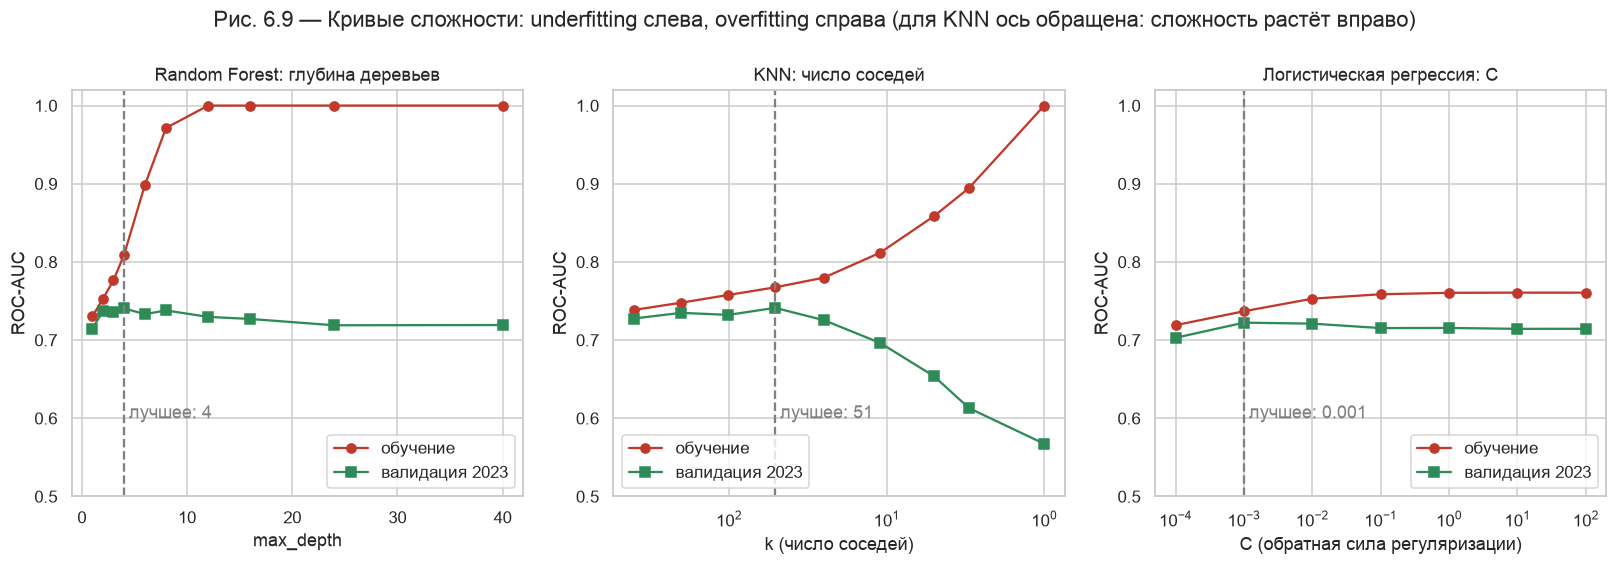

train  valid
             value                 
RF max_depth 1.0000    0.730  0.715
             2.0000    0.753  0.737
             3.0000    0.776  0.737
             4.0000    0.809  0.741
             6.0000    0.899  0.733
             8.0000    0.971  0.738
             12.0000   1.000  0.730
             16.0000   1.000  0.727
             24.0000   1.000  0.719
             40.0000   1.000  0.719
KNN k        1.0000    1.000  0.567
             3.0000    0.895  0.613
             5.0000    0.859  0.654
             11.0000   0.812  0.696
             25.0000   0.780  0.726
             51.0000   0.767  0.741
             101.0000  0.758  0.732
             201.0000  0.748  0.735
             401.0000  0.739  0.728
LR C         0.0001    0.719  0.703
             0.0010    0.737  0.722
             0.0100    0.753  0.721
             0.1000    0.759  0.715
             1.0000    0.760  0.716
             10.0000   0.761  0.714
             100.0000  0.761  0.715

In [11]:
def curve(make, values):
    rows = []
    for v in values:
        m = make(v).fit(X_tr if not isinstance(make(v), type(None)) else X_tr, y_tr)
        rows.append({"value": v, "train": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]),
                     "valid": roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
    return pd.DataFrame(rows)

depths = [1, 2, 3, 4, 6, 8, 12, 16, 24, 40]
cur_rf = curve(lambda d: RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=1, max_features=0.5,
                                                random_state=SEED, n_jobs=-1), depths)
ks = [1, 3, 5, 11, 25, 51, 101, 201, 401]
cur_knn = curve(lambda k: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), ks)
Cs = [1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100]
cur_lr = curve(lambda c: make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000)), Cs)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, cur, xlab, title, logx in [(axes[0], cur_rf, "max_depth", "Random Forest: глубина деревьев", False),
                                    (axes[1], cur_knn, "k (число соседей)", "KNN: число соседей", True),
                                    (axes[2], cur_lr, "C (обратная сила регуляризации)", "Логистическая регрессия: C", True)]:
    ax.plot(cur.value, cur.train, "o-", color="#C0392B", label="обучение")
    ax.plot(cur.value, cur.valid, "s-", color="#2E8B57", label="валидация 2023")
    best = cur.loc[cur.valid.idxmax()]
    ax.axvline(best.value, ls="--", color="gray"); ax.text(best.value, 0.6, f" лучшее: {best.value:g}", color="gray")
    ax.set(xlabel=xlab, ylabel="ROC-AUC", title=title, ylim=(0.5, 1.02))
    if logx: ax.set_xscale("log")
    ax.legend(loc="lower right" if ax is not axes[1] else "lower left")
axes[1].invert_xaxis()
fig.suptitle("Рис. 6.9 — Кривые сложности: underfitting слева, overfitting справа (для KNN ось обращена: сложность растёт вправо)", y=1.03)
save("fig_6_9_validation_curves")
pd.concat({"RF max_depth": cur_rf.set_index("value"), "KNN k": cur_knn.set_index("value"), "LR C": cur_lr.set_index("value")}).round(3)

**Интерпретация.**
- **Random Forest:** при глубине 1–3 модель недообучена (обучение 0.73–0.78, валидация 0.72–0.74 — обе низкие и близкие). Начиная с глубины 8–12 ROC-AUC на обучении достигает **1.0** — модель запоминает каждый день, а на валидации качество снижается (0.741 → 0.719): классическое переобучение. Лучшая валидация — при глубине около 4 *без других ограничений*; выбранная модель вместо этого ограничивает **размер листа** (≥ 20 дней) — другой способ регуляризации.
- **KNN:** k = 1 — крайний случай переобучения (обучение 1.00, валидация 0.57); с ростом k разрыв сокращается, оптимум около k = 51 (0.741), при k = 401 модель начинает «усреднять всё» и недообучается.
- **Логистическая регрессия:** при очень сильной регуляризации (C = 0.0001) — недообучение (0.70); дальше кривые почти плоские и разрыв мал (~0.04): линейная модель **не способна переобучиться** на 26 признаках и 2 900 днях — её предел задаёт простота (bias), а не объём данных.
- Кривые валидации шумные: валидация — один год (365 дней, ~87 дождливых), поэтому разница в 0.01 не значима. Именно поэтому гиперпараметры в ноутбуке 02 выбирались кросс-валидацией по 5 периодам, а не по одному году.

## 3.2 Кривые обучения (learning curves)

Как меняется качество с ростом объёма обучающих данных для трёх моделей: простой (логистическая регрессия), переобученной (Random Forest без ограничений) и регуляризованной (выбранный Random Forest из ноутбука 02).

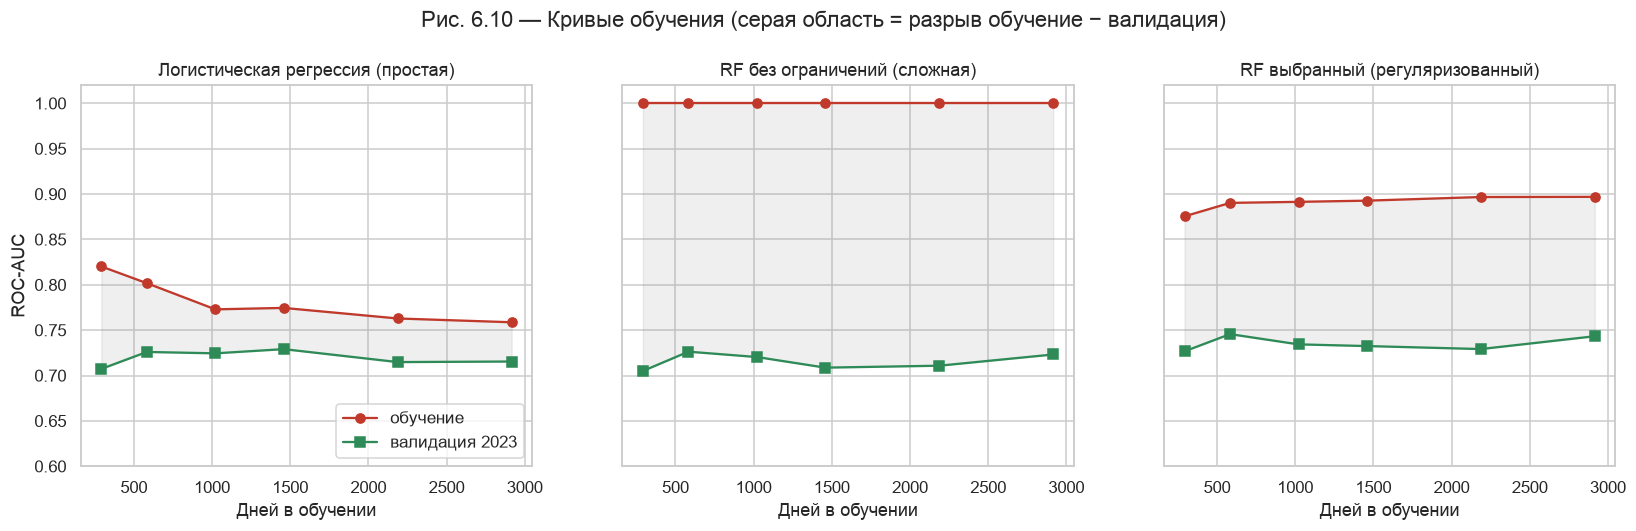

,Модель,Доля обучения,Дней,ROC-AUC обучение,ROC-AUC валидация
0,Логистическая регрессия (простая),0.10,292,0.820,0.707
1,RF без ограничений (сложная),0.10,292,1.000,0.705
2,RF выбранный (регуляризованный),0.10,292,0.875,0.727
3,Логистическая регрессия (простая),0.20,583,0.802,0.726
4,RF без ограничений (сложная),0.20,583,1.000,0.726
5,RF выбранный (регуляризованный),0.20,583,0.890,0.746
6,Логистическая регрессия (простая),0.35,1021,0.773,0.724
7,RF без ограничений (сложная),0.35,1021,1.000,0.720
8,RF выбранный (регуляризованный),0.35,1021,0.891,0.734
9,Логистическая регрессия (простая),0.50,1458,0.774,0.729


In [12]:
fracs = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
lc_models = {"Логистическая регрессия (простая)": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
             "RF без ограничений (сложная)": RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=1,
                                                                   max_features=0.5, random_state=SEED, n_jobs=-1),
             "RF выбранный (регуляризованный)": new_rf()}
lc_rows = []
for frac in fracs:
    idx = train.sample(frac=frac, random_state=SEED).index
    for name, base in lc_models.items():
        m = clone(base).fit(X_tr.loc[idx], y_tr.loc[idx])
        lc_rows.append({"Модель": name, "Доля обучения": frac, "Дней": len(idx),
                        "ROC-AUC обучение": roc_auc_score(y_tr.loc[idx], m.predict_proba(X_tr.loc[idx])[:, 1]),
                        "ROC-AUC валидация": roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
lc = pd.DataFrame(lc_rows)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (name, g) in zip(axes, lc.groupby("Модель", sort=False)):
    ax.plot(g["Дней"], g["ROC-AUC обучение"], "o-", color="#C0392B", label="обучение")
    ax.plot(g["Дней"], g["ROC-AUC валидация"], "s-", color="#2E8B57", label="валидация 2023")
    ax.fill_between(g["Дней"], g["ROC-AUC валидация"], g["ROC-AUC обучение"], color="gray", alpha=0.12)
    ax.set(title=name, xlabel="Дней в обучении", ylim=(0.6, 1.02))
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(loc="lower right")
fig.suptitle("Рис. 6.10 — Кривые обучения (серая область = разрыв обучение − валидация)", y=1.03)
save("fig_6_10_learning_curves")
lc.round(3)

**Интерпретация.**
- **RF без ограничений** всегда имеет ROC-AUC обучения **1.0** при любом объёме данных, а на валидации — лишь 0.70–0.73: огромный и не сокращающийся разрыв — модель запоминает, а не обобщает.
- **Логистическая регрессия:** с ростом данных ROC-AUC обучения падает (0.82 → 0.76) и сходится с валидацией (~0.72) — признак **недообучения**: больше данных не помогает, не хватает гибкости модели.
- **Выбранный RF** держит умеренный разрыв (обучение ~0.89, валидация 0.73–0.75) и даёт лучшую валидацию почти при любом объёме данных.
- Ни одна кривая не растёт заметно после ~600 дней: качество ограничено **информацией в признаках** (суточные данные одной точки), а не объёмом данных. Больше лет того же типа данных прогноз не улучшат — нужны более информативные данные (почасовые, соседние станции, данные численных моделей).

## 3.3 Три случая лабораторной: чистые данные, шум + underfitting, шум + overfitting

Для наглядности берём **два признака** — давление и облачность (стандартизованные) — и рисуем границы решений, как в лабораторной:
1. **чистые данные + логистическая регрессия**;
2. **шум + underfitting**: к признакам обучения добавлен гауссов шум (σ = 0.7), модель — логистическая регрессия;
3. **шум + overfitting**: те же зашумлённые данные, Random Forest без ограничений глубины;
4. **мера коррекции**: Random Forest с регуляризацией (минимум 50 дней в листе).

Все модели — с `class_weight="balanced"`, чтобы граница была видна при несбалансированных классах. Проверка — на реальном (чистом) тесте.

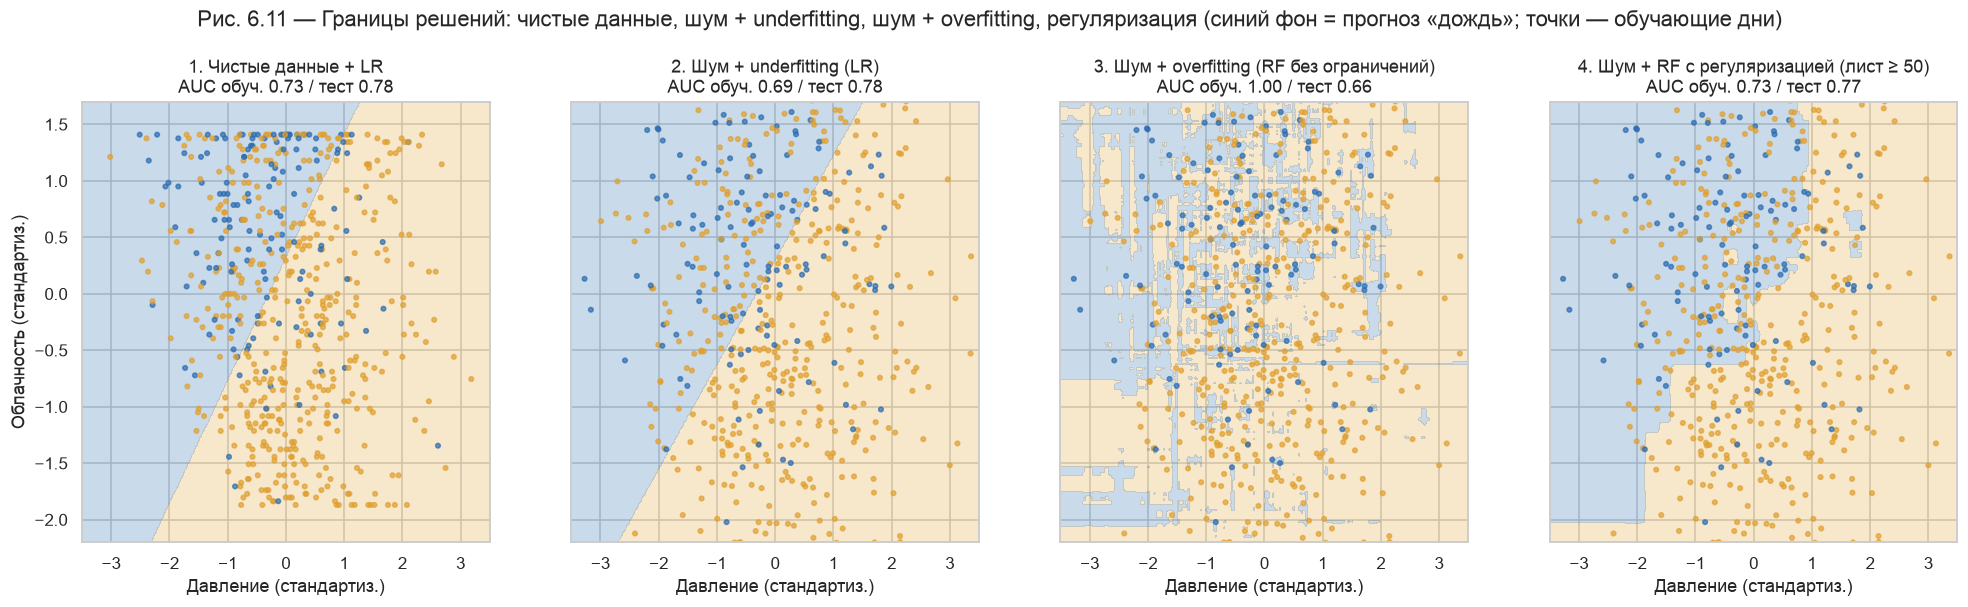

,ROC-AUC обучение,ROC-AUC тест,F1 обучение,F1 тест,Разрыв ROC-AUC
1. Чистые данные + LR,0.727,0.783,0.492,0.522,-0.056
2. Шум + underfitting (LR),0.689,0.784,0.462,0.534,-0.095
3. Шум + overfitting (RF без ограничений),1.000,0.664,0.996,0.384,0.336
4. Шум + RF с регуляризацией (лист ≥ 50),0.733,0.769,0.489,0.498,-0.036


In [13]:
F2 = ["pressure_msl_mean", "cloud_cover_mean"]
sc2 = StandardScaler().fit(X_tr[F2])
A_tr, A_te = sc2.transform(X_tr[F2]), sc2.transform(X_te[F2])
A_tr_noisy = A_tr + np.random.default_rng(SEED).normal(0, 0.7, A_tr.shape)
cases = {
    "1. Чистые данные + LR": (A_tr, LogisticRegression(class_weight="balanced")),
    "2. Шум + underfitting (LR)": (A_tr_noisy, LogisticRegression(class_weight="balanced")),
    "3. Шум + overfitting (RF без ограничений)": (A_tr_noisy, RandomForestClassifier(n_estimators=200, min_samples_leaf=1,
                                                       class_weight="balanced", random_state=SEED, n_jobs=-1)),
    "4. Шум + RF с регуляризацией (лист ≥ 50)": (A_tr_noisy, RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                                                       class_weight="balanced", random_state=SEED, n_jobs=-1)),
}
xx, yy = np.meshgrid(np.linspace(-3.5, 3.5, 300), np.linspace(-2.2, 1.7, 300))
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2), sharey=True)
case_rows = {}
for ax, (name, (A, base)) in zip(axes, cases.items()):
    m = clone(base).fit(A, y_tr)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[C_DRY, C_WET], alpha=0.25)
    sub = np.random.default_rng(1).choice(len(A), 600, replace=False)
    ax.scatter(A[sub, 0], A[sub, 1], c=np.where(y_tr.values[sub] == 1, C_WET, C_DRY), s=9, alpha=0.7)
    pr_tr, pr_te = m.predict(A), m.predict(A_te)
    case_rows[name] = {"ROC-AUC обучение": roc_auc_score(y_tr, m.predict_proba(A)[:, 1]),
                       "ROC-AUC тест": roc_auc_score(y_te, m.predict_proba(A_te)[:, 1]),
                       "F1 обучение": f1_score(y_tr, pr_tr), "F1 тест": f1_score(y_te, pr_te)}
    case_rows[name]["Разрыв ROC-AUC"] = case_rows[name]["ROC-AUC обучение"] - case_rows[name]["ROC-AUC тест"]
    ax.set(title=f"{name}\nAUC обуч. {case_rows[name]['ROC-AUC обучение']:.2f} / тест {case_rows[name]['ROC-AUC тест']:.2f}",
           xlabel="Давление (стандартиз.)", xlim=(-3.5, 3.5), ylim=(-2.2, 1.7))
axes[0].set_ylabel("Облачность (стандартиз.)")
fig.suptitle("Рис. 6.11 — Границы решений: чистые данные, шум + underfitting, шум + overfitting, регуляризация "
             "(синий фон = прогноз «дождь»; точки — обучающие дни)", y=1.04)
save("fig_6_11_fitting_cases")
pd.DataFrame(case_rows).T.round(3)

**Интерпретация.**
1. **Чистые данные + LR:** граница — прямая линия «низкое давление + высокая облачность → дождь». ROC-AUC на тесте 0.78 — уже на двух признаках модель передаёт главное физическое правило.
2. **Шум + underfitting (LR):** шум «размыл» обучающие точки — ROC-AUC на обучении упал до 0.69, но граница осталась почти той же прямой, и тест не пострадал (0.78). Простая модель **не ищет** сложных закономерностей, поэтому и шум не может её обмануть — но и большего, чем прямая граница, она не выучит.
3. **Шум + overfitting (RF без ограничений):** граница **раздроблена на островки** вокруг отдельных зашумлённых дней; на обучении AUC = 1.00, F1 = 1.00, на тесте 0.66 и 0.38 — разрыв **0.34**. Модель «танцует с шумом».
4. **Мера коррекции — регуляризация** (минимум 50 дней в листе): граница снова крупноблочная, разрыв исчез, ROC-AUC на тесте 0.77 — почти как у прямой линии на чистых данных.

Отрицательный «разрыв» у LR (тест лучше обучения) объясняется тем, что 2024–2025 годы на этих двух признаках оказались немного «легче» 2015–2022; переобучения у LR нет.

## 3.4 Как меняется решение модели при росте шума

Задание лабораторной «Что вы наблюдаете, когда увеличиваете шум?»: границы решений простой (LR) и сложной (RF без ограничений) модели при σ шума = 0, 0.5 и 1.0.

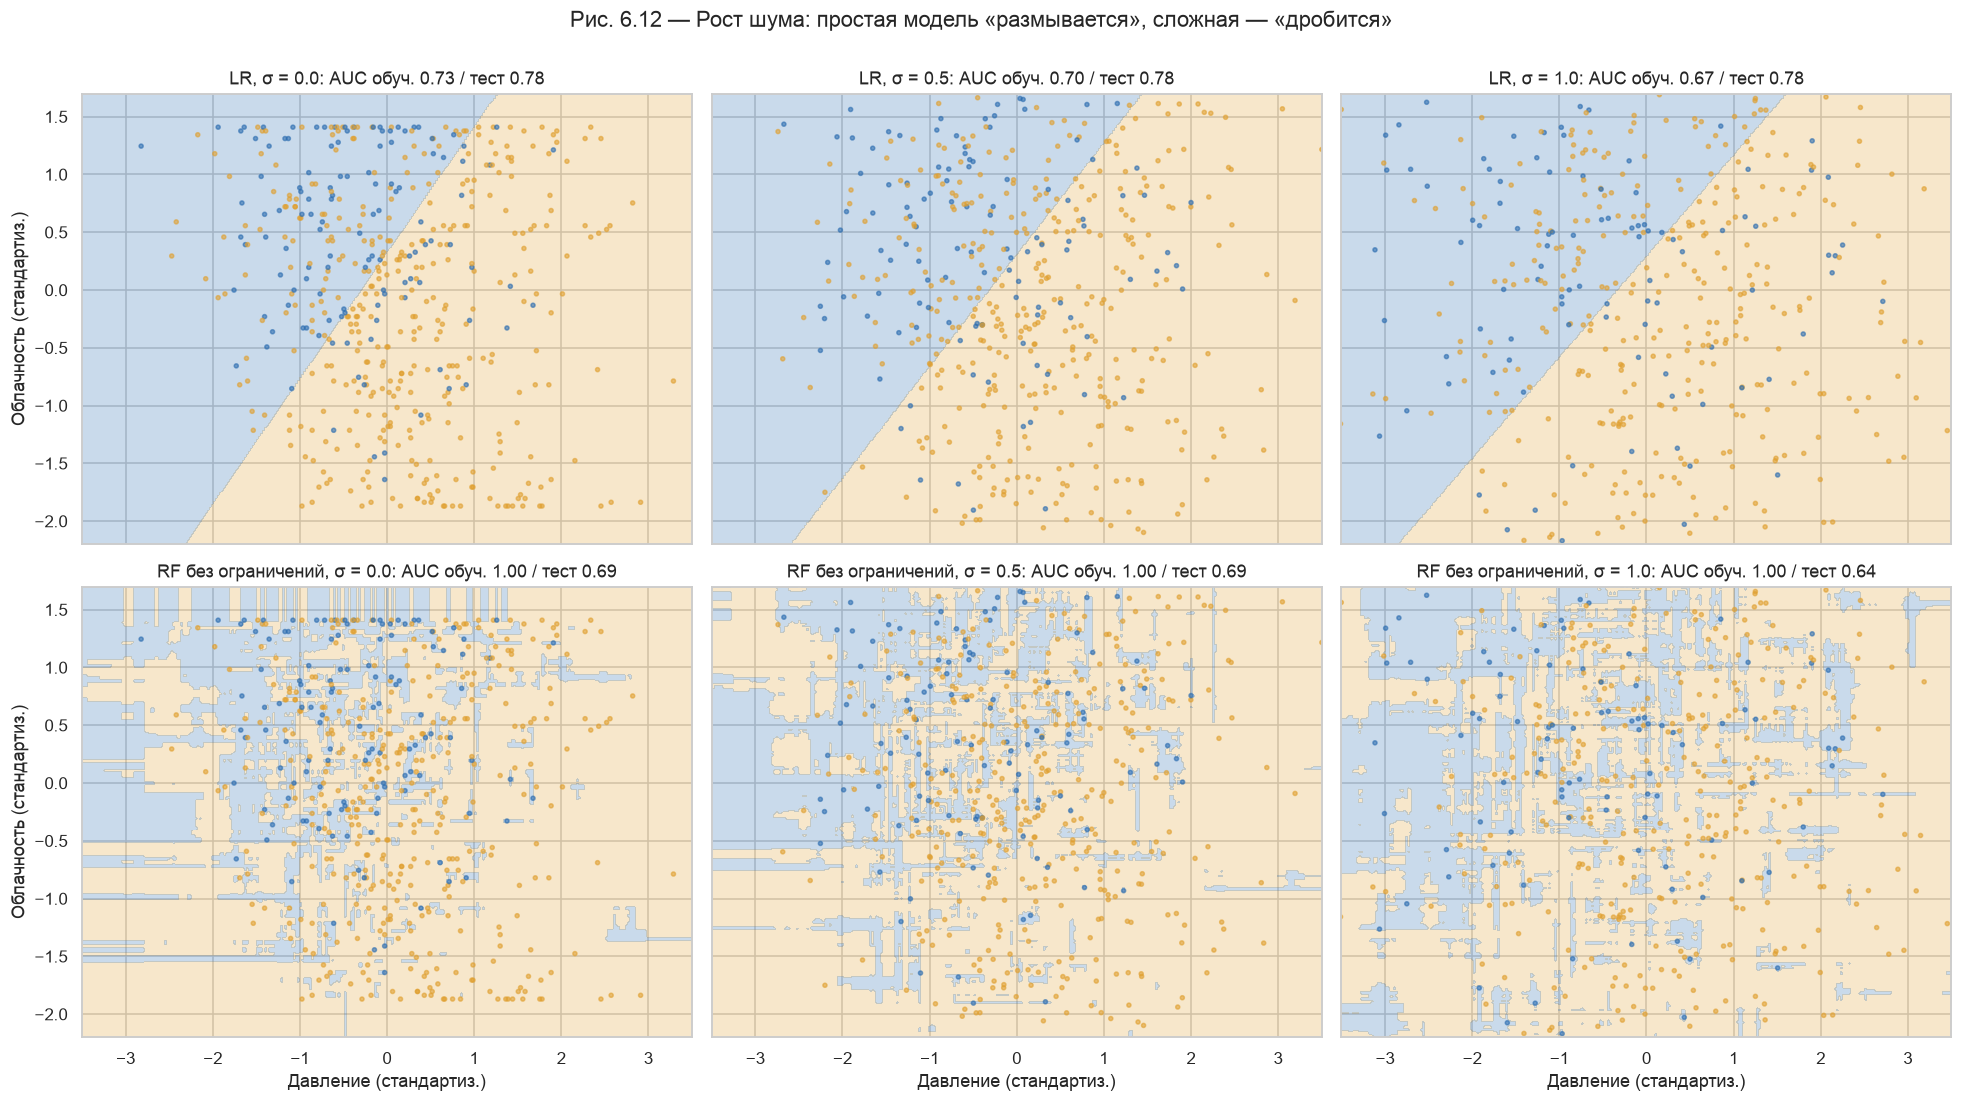

,Модель,σ шума,ROC-AUC обучение,ROC-AUC тест
0,LR,0.0,0.727,0.783
1,RF без ограничений,0.0,0.999,0.686
2,LR,0.5,0.704,0.784
3,RF без ограничений,0.5,1.000,0.688
4,LR,1.0,0.666,0.784
5,RF без ограничений,1.0,1.000,0.641


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
grow_rows = []
for j, s in enumerate([0.0, 0.5, 1.0]):
    A = A_tr + np.random.default_rng(SEED).normal(0, s, A_tr.shape) if s > 0 else A_tr
    for i, (mname, base) in enumerate([("LR", LogisticRegression(class_weight="balanced")),
                                        ("RF без ограничений", RandomForestClassifier(n_estimators=200, min_samples_leaf=1,
                                                              class_weight="balanced", random_state=SEED, n_jobs=-1))]):
        m = clone(base).fit(A, y_tr)
        Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax = axes[i, j]
        ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[C_DRY, C_WET], alpha=0.25)
        sub = np.random.default_rng(1).choice(len(A), 500, replace=False)
        ax.scatter(A[sub, 0], A[sub, 1], c=np.where(y_tr.values[sub] == 1, C_WET, C_DRY), s=7, alpha=0.6)
        auc_tr, auc_te = roc_auc_score(y_tr, m.predict_proba(A)[:, 1]), roc_auc_score(y_te, m.predict_proba(A_te)[:, 1])
        grow_rows.append({"Модель": mname, "σ шума": s, "ROC-AUC обучение": auc_tr, "ROC-AUC тест": auc_te})
        ax.set(title=f"{mname}, σ = {s}: AUC обуч. {auc_tr:.2f} / тест {auc_te:.2f}", xlim=(-3.5, 3.5), ylim=(-2.2, 1.7))
for ax in axes[1]: ax.set_xlabel("Давление (стандартиз.)")
for ax in axes[:, 0]: ax.set_ylabel("Облачность (стандартиз.)")
fig.suptitle("Рис. 6.12 — Рост шума: простая модель «размывается», сложная — «дробится»", y=1.0)
plt.tight_layout(); save("fig_6_12_noise_growth_boundaries")
pd.DataFrame(grow_rows).round(3)

**Интерпретация (вопрос лабораторной «что происходит при росте шума?»).**
- **Логистическая регрессия:** с ростом шума граница почти не меняется, ROC-AUC на тесте стабилен (0.784), снижается лишь качество на обучающих (зашумлённых) точках. Простая модель «боится» шума и не слушает его.
- **RF без ограничений:** уже без шума имеет островки (обучение 0.999, тест 0.69), а с ростом шума граница **дробится сильнее**, тест падает до 0.64 при σ = 1.0, хотя на обучении по-прежнему 1.00.
- Итог: шум почти не вредит недообученной модели, но **усиливает переобучение** сложной модели — она тратит гибкость на запоминание шума.

## 3.5 Разрыв между обучением и тестом у итоговых моделей

In [15]:
final = {"Логистическая регрессия (C=0.1)": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
         "RF без ограничений": RandomForestClassifier(n_estimators=400, min_samples_leaf=1, max_features=0.5,
                                                      random_state=SEED, n_jobs=-1),
         "RF выбранный (CV: depth 12, leaf 20)": new_rf()}
gap_rows = {}
for name, base in final.items():
    m = clone(base).fit(X_tr, y_tr)
    a_tr, a_te = roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]), roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
    t = tune_threshold(y_va, m.predict_proba(X_va)[:, 1])
    gap_rows[name] = {"ROC-AUC обучение": a_tr, "ROC-AUC тест": a_te, "Разрыв": a_tr - a_te,
                      "F1 тест": f1_score(y_te, m.predict_proba(X_te)[:, 1] >= t)}
pd.DataFrame(gap_rows).T.round(3)

,ROC-AUC обучение,ROC-AUC тест,Разрыв,F1 тест
Логистическая регрессия (C=0.1),0.759,0.773,-0.014,0.524
RF без ограничений,1.000,0.769,0.231,0.497
"RF выбранный (CV: depth 12, leaf 20)",0.896,0.793,0.103,0.519


**Интерпретация.** Итоговые модели на всех 26 признаках: RF без ограничений переобучен (разрыв 0.23, тест 0.77); логистическая регрессия не переобучена (разрыв −0.01), но её предел — 0.77; **выбранный RF** (глубина 12, лист ≥ 20, подобраны кросс-валидацией в ноутбуке 02) сохраняет умеренный разрыв (0.10) и даёт **лучший тест (0.79)**. Умеренный разрыв допустим, если качество на новых данных максимально: регуляризация уменьшила переобучение, не доводя модель до недообучения.

## 3.6 Ответы на вопросы лабораторной (Underfitting / Overfitting)

**Какие различия вы видите между тремя границами?** На чистых данных — прямая и чёткая граница; при шуме + underfitting — та же прямая, но точки вокруг неё перемешаны, решение «размытое»; при шуме + overfitting — мозаика из островков, повторяющих отдельные зашумлённые дни.

**Что, по-вашему, выучила каждая модель?** Логистическая регрессия — одно физическое правило «низкое давление и высокая облачность ведут к дождю». RF без ограничений — сами обучающие дни вместе с их шумом (таблицу ответов, а не закономерность). Регуляризованный RF — то же правило, что и LR, но с учётом нелинейностей (например, что при очень низком давлении дождь вероятен почти при любой облачности).

**Как бы вы обращались с неопределённостью, если бы были алгоритмом?** Выдавал бы не «да/нет», а **откалиброванную вероятность**; в зонах перекрытия классов честно говорил бы «не уверен» (вероятность около частоты класса); предпочитал бы простое объяснение, когда данных мало; опирался бы на ансамбль мнений (случайный лес) и следил бы за качеством датчиков, прежде чем доверять входным данным.

**Провокация: что лучше — быть осторожным и игнорировать детали (underfitting) или внимательным ко всему, рискуя выучить ошибки (overfitting)?** На наших данных — **ближе к осторожности, но не до недообучения**. Переобученная модель уверенно ошибается: на тесте её ROC-AUC 0.66–0.69 против 0.78 у простой прямой, и она выдаёт «точные» тревоги на основе случайных совпадений — это хуже, чем честная неопределённость. Недообученная модель ошибается предсказуемо и плавно деградирует при шуме. Лучший выбор — **регуляризованная модель, сложность которой выбрана по проверке на новых данных**: она берёт от сложной модели нелинейности, а от простой — устойчивость.

**Раздел для заметок отчёта.**
- *Что я узнал?* Качество на обучении ничего не говорит о качестве на новых данных — диагноз ставится по **разрыву** между обучением и проверкой. Шум усиливает переобучение. Сложность выбирается кросс-валидацией по времени.
- *Какие у меня вопросы?* Позволили бы почасовые данные строить более сложные модели без переобучения? Насколько репрезентативен один валидационный год (кривые шумные)?
- *Какую модель я выбираю для себя?* Random Forest с ограниченной глубиной (12) и размером листа (≥ 20) — лучшее качество на тесте и умеренный разрыв; логистическую регрессию — как интерпретируемый и устойчивый к шуму запасной вариант.

**Вопросы к коду.** *Что происходит при увеличении шума?* — Граница LR почти не меняется, граница RF дробится, тест RF падает 0.69 → 0.64. *Как меняется решение модели?* — Простая модель сохраняет правило, сложная подстраивается под шум. *Что значит «выучить слишком мало» или «слишком много»?* — Слишком мало: модель на двух признаках с прямой границей не может использовать влажность, ветер и сезон (обучение ≈ тест ≈ 0.73–0.78). Слишком много: AUC на обучении = 1.0 при 0.64–0.69 на тесте.

---
# 4. SMOTE — «эхо слишком редких голосов»

**SMOTE** создаёт синтетические примеры миноритарного класса интерполяцией между соседними реальными примерами.
Редкий класс нашей задачи — **критическая погода завтра** (сильные осадки, ветер, жара, мороз, снегопад): бинарная задача «критическая / нет».

## 4.1 Выявление дисбаланса и сравнение до / после SMOTE

Доля критических дней: обучение 6.5% (190 дней), тест 7.8% (57 дней)


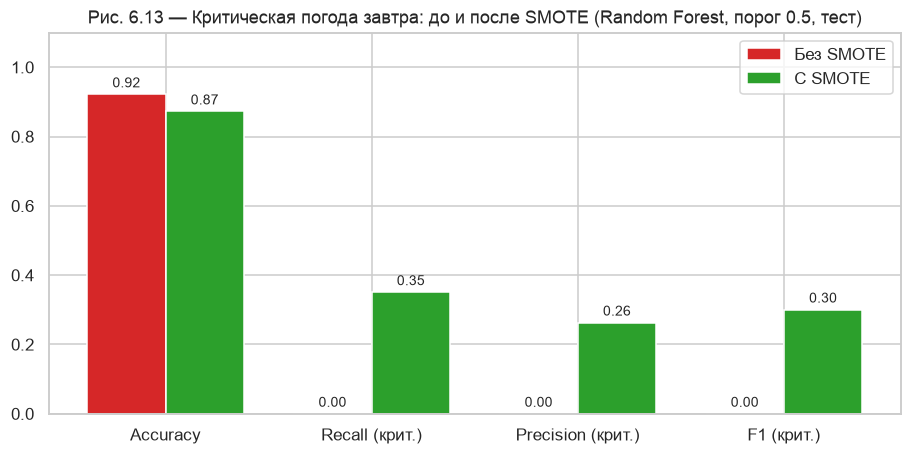

,Accuracy,Precision (крит.),Recall (крит.),F1 (крит.),ROC-AUC,PR-AUC,Дней предсказано
Без SMOTE,0.922,0.000,0.000,0.000,0.808,0.294,0.0
С SMOTE,0.873,0.263,0.351,0.301,0.783,0.241,76.0


In [16]:
yc_tr, yc_va, yc_te = (train[TARGET3] == 2).astype(int), (valid[TARGET3] == 2).astype(int), (test[TARGET3] == 2).astype(int)
print(f"Доля критических дней: обучение {yc_tr.mean():.1%} ({yc_tr.sum()} дней), тест {yc_te.mean():.1%} ({yc_te.sum()} дней)")

def smote_pipe(smote=True, k=5, cols=None):
    steps = [("scale", StandardScaler())]
    if smote: steps.append(("smote", SMOTE(k_neighbors=k, random_state=SEED)))
    return ImbPipeline(steps + [("model", new_rf())])

def crit_metrics(m, cols=FEATURES, Xtr=None):
    p = m.predict_proba(X_te[cols])[:, 1]; pred = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(yc_te, pred), "Precision (крит.)": precision_score(yc_te, pred, zero_division=0),
            "Recall (крит.)": recall_score(yc_te, pred), "F1 (крит.)": f1_score(yc_te, pred),
            "ROC-AUC": roc_auc_score(yc_te, p), "PR-AUC": average_precision_score(yc_te, p), "Дней предсказано": int(pred.sum())}

m_no = smote_pipe(False).fit(X_tr, yc_tr); m_sm = smote_pipe(True).fit(X_tr, yc_tr)
sm_tbl = pd.DataFrame({"Без SMOTE": crit_metrics(m_no), "С SMOTE": crit_metrics(m_sm)}).T
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(4); w = 0.38
cols4 = ["Accuracy", "Recall (крит.)", "Precision (крит.)", "F1 (крит.)"]
ax.bar(x - w / 2, sm_tbl.loc["Без SMOTE", cols4], w, label="Без SMOTE", color="#d62728")
ax.bar(x + w / 2, sm_tbl.loc["С SMOTE", cols4], w, label="С SMOTE", color="#2ca02c")
for i, c in enumerate(cols4):
    ax.text(i - w / 2, sm_tbl.loc["Без SMOTE", c] + 0.02, f"{sm_tbl.loc['Без SMOTE', c]:.2f}", ha="center", fontsize=9)
    ax.text(i + w / 2, sm_tbl.loc["С SMOTE", c] + 0.02, f"{sm_tbl.loc['С SMOTE', c]:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, cols4); ax.set_ylim(0, 1.1); ax.legend()
ax.set_title("Рис. 6.13 — Критическая погода завтра: до и после SMOTE (Random Forest, порог 0.5, тест)")
save("fig_6_13_smote_before_after")
sm_tbl.round(3)

**Интерпретация.**
- Критические дни составляют **6.5 %** обучения и 7.8 % теста — сильный дисбаланс (~1 : 14).
- **Без SMOTE** Random Forest при пороге 0.5 **не предсказывает ни одного критического дня** (Recall 0) — при этом accuracy 0.92 (модель просто всегда говорит «не критическая»).
- **С SMOTE** модель находит **35 %** критических дней (Precision 0.26, F1 0.30) — классу дан «голос», как и обещают материалы курса. Accuracy снижается до 0.87 — расплата за ложные тревоги, но для предупреждений это верный компромисс.
- Однако **ROC-AUC (0.81 → 0.78) и PR-AUC (0.29 → 0.24) снижаются**: SMOTE не улучшает способность модели ранжировать дни по риску, а сдвигает её решения в сторону редкого класса. Похожий результат дал бы сдвиг порога (см. ноутбук 03, раздел B.4).

## 4.2 Расширение 1: SMOTE на подмножествах признаков

Выбираем 5 и 10 наиболее релевантных признаков двумя способами — `SelectKBest` (F-критерий) и `feature_importances_` Random Forest (только на обучающих данных) — и применяем SMOTE на подмножестве и на полном наборе.

Топ-5 SelectKBest: ['precipitation_hours', 'precipitation_sum', 'pressure_msl_mean', 'wind_speed_10m_max', 'cloud_cover_mean']
Топ-5 важность RF: ['precipitation_sum', 'pressure_msl_mean', 'temperature_2m_mean', 'wind_speed_10m_max', 'wind_dir_sin']


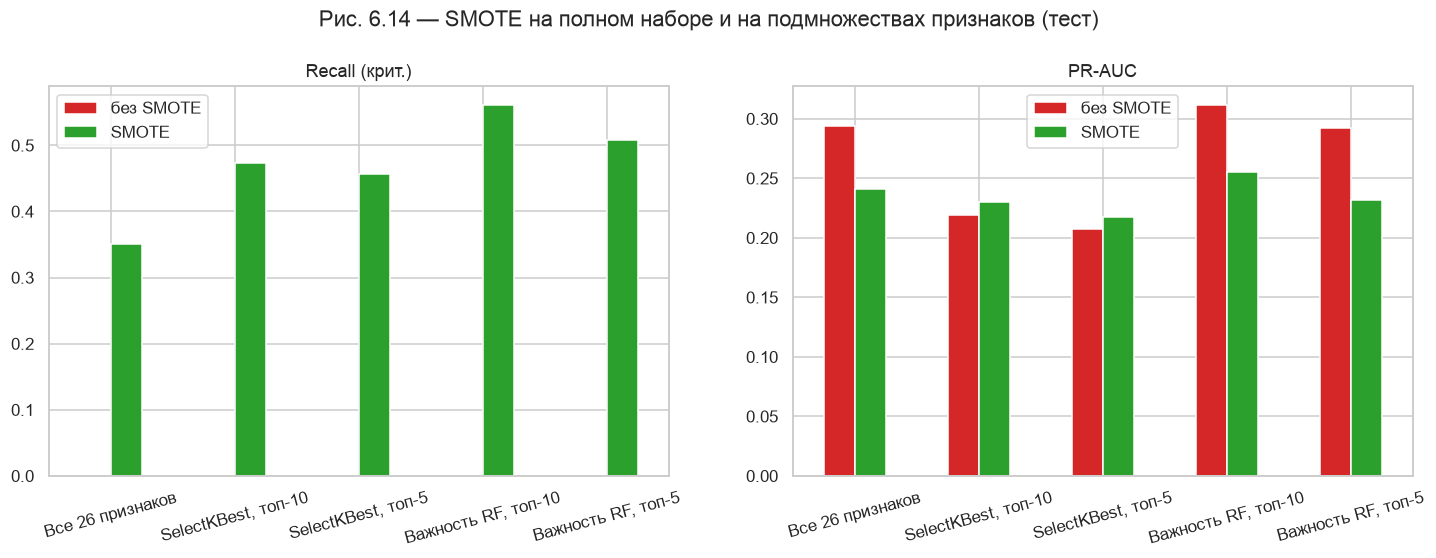

Accuracy  Precision (крит.)  Recall (крит.)  \
Все 26 признаков    без SMOTE     0.922              0.000           0.000   
                    SMOTE         0.873              0.263           0.351   
SelectKBest, топ-10 без SMOTE     0.922              0.000           0.000   
                    SMOTE         0.829              0.221           0.474   
SelectKBest, топ-5  без SMOTE     0.922              0.000           0.000   
                    SMOTE         0.819              0.205           0.456   
Важность RF, топ-10 без SMOTE     0.922              0.000           0.000   
                    SMOTE         0.830              0.244           0.561   
Важность RF, топ-5  без SMOTE     0.922              0.000           0.000   
                    SMOTE         0.781              0.180           0.509   

                               F1 (крит.)  ROC-AUC  PR-AUC  Дней предсказано  
Все 26 признаков    без SMOTE       0.000    0.808   0.294               0.0  
                    SMOTE           0.301    0.783   0.241              76.0  
SelectKBest, топ-10 без SMOTE       0.000    0.731   0.220               0.0  
                    SMOTE           0.302    0.749   0.230             122.0  
SelectKBest, топ-5  без SMOTE       0.000    0.743   0.207               0.0  
                    SMOTE           0.283    0.735   0.218             127.0  
Важность RF, топ-10 без SMOTE       0.000    0.813   0.312               0.0  
                    SMOTE           0.340    0.804   0.256             131.0  
Важность RF, топ-5  без SMOTE       0.000    0.793   0.292               0.0  
                    SMOTE           0.266    0.786   0.232             161.0

In [17]:
kb = SelectKBest(f_classif, k="all").fit(X_tr, yc_tr)
rank_kb = pd.Series(kb.scores_, index=FEATURES).sort_values(ascending=False).index
rank_rf = pd.Series(new_rf().fit(X_tr, yc_tr).feature_importances_, index=FEATURES).sort_values(ascending=False).index
subsets = {"Все 26 признаков": FEATURES,
           "SelectKBest, топ-10": list(rank_kb[:10]), "SelectKBest, топ-5": list(rank_kb[:5]),
           "Важность RF, топ-10": list(rank_rf[:10]), "Важность RF, топ-5": list(rank_rf[:5])}
sub_rows = {}
for name, cols in subsets.items():
    for sm in (False, True):
        m = smote_pipe(sm).fit(X_tr[cols], yc_tr)
        sub_rows[(name, "SMOTE" if sm else "без SMOTE")] = crit_metrics(m, cols)
sub_tbl = pd.DataFrame(sub_rows).T
print("Топ-5 SelectKBest:", list(rank_kb[:5])); print("Топ-5 важность RF:", list(rank_rf[:5]))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
for ax, metric in zip(axes, ["Recall (крит.)", "PR-AUC"]):
    sub_tbl[metric].unstack(1)[["без SMOTE", "SMOTE"]].loc[list(subsets)].plot(kind="bar", ax=ax, rot=15, color=["#d62728", "#2ca02c"])
    ax.set(title=metric, xlabel="")
fig.suptitle("Рис. 6.14 — SMOTE на полном наборе и на подмножествах признаков (тест)", y=1.03)
save("fig_6_14_smote_subsets")
sub_tbl.round(3)

**Интерпретация.**
- **SMOTE на подмножестве признаков, выбранных по важности Random Forest (топ-10), дал лучший результат:** Recall критического класса **0.56** (против 0.35 на всех 26 признаках), F1 **0.34** (против 0.30), ROC-AUC 0.80 — почти без потерь в ранжировании.
- Причина: в пространстве меньшей размерности без нерелевантных признаков соседи по SMOTE — действительно похожие дни, и интерполяция между ними даёт более правдоподобные синтетические примеры.
- **Подмножества SelectKBest хуже** (ROC-AUC 0.73–0.75): F-критерий оценивает признаки по одному и линейно, поэтому выбирает дублирующие друг друга признаки осадков и пропускает, например, направление ветра; Random Forest учитывает нелинейности и взаимодействия.
- Слишком маленькое подмножество (топ-5) теряет информацию: больше ложных тревог (161 день) и ниже F1.

## 4.3 Расширение 2: SMOTE + контролируемый шум

Гауссов шум (σ = 0.5 стандартного отклонения признака) добавляется к **25 %** случайных строк обучающей выборки (реалистичная ситуация: часть архива записана неточными датчиками); затем сравниваем сценарии с SMOTE и без.

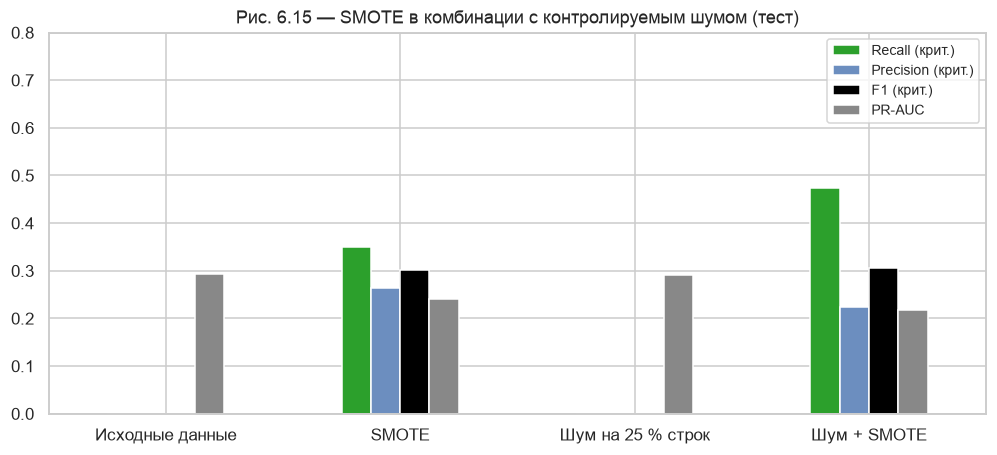

,Accuracy,Precision (крит.),Recall (крит.),F1 (крит.),ROC-AUC,PR-AUC,Дней предсказано
Исходные данные,0.922,0.000,0.000,0.000,0.808,0.294,0.0
SMOTE,0.873,0.263,0.351,0.301,0.783,0.241,76.0
Шум на 25 % строк,0.922,0.000,0.000,0.000,0.805,0.290,0.0
Шум + SMOTE,0.832,0.225,0.474,0.305,0.795,0.218,120.0


In [18]:
rng = np.random.default_rng(SEED)
X_noisy = X_tr.copy()
rows_n = rng.random(len(X_noisy)) < 0.25
X_noisy.loc[rows_n, FEATURES] = X_noisy.loc[rows_n, FEATURES].values + rng.normal(0, 0.5, (rows_n.sum(), len(FEATURES))) * X_tr.std().values
scen_sn = {"Исходные данные": (X_tr, False), "SMOTE": (X_tr, True),
           "Шум на 25 % строк": (X_noisy, False), "Шум + SMOTE": (X_noisy, True)}
sn_tbl = pd.DataFrame({name: crit_metrics(smote_pipe(sm).fit(X, yc_tr)) for name, (X, sm) in scen_sn.items()}).T
fig, ax = plt.subplots(figsize=(11, 4.5))
sn_tbl[["Recall (крит.)", "Precision (крит.)", "F1 (крит.)", "PR-AUC"]].plot(kind="bar", ax=ax, rot=0,
                                                                              color=["#2ca02c", "#6C8EBF", "black", "#888888"])
ax.set(ylim=(0, 0.8), title="Рис. 6.15 — SMOTE в комбинации с контролируемым шумом (тест)"); ax.legend(fontsize=9)
save("fig_6_15_smote_noise")
sn_tbl.round(3)

**Интерпретация.**
- **Шум сам по себе** (на 25 % строк) почти не влияет на модель без SMOTE (ROC-AUC 0.808 → 0.805): Random Forest устойчив, а критический класс она всё равно не предсказывает.
- **Шум + SMOTE:** Recall растёт (0.35 → 0.47), но вместе с ним растёт число тревог (76 → 120 дней), а PR-AUC падает (0.24 → 0.22). SMOTE интерполирует и между **зашумлёнными** редкими примерами, поэтому шум «размножается» в синтетических данных и расширяет область критического класса.
- Вывод: перед SMOTE данные нужно **очищать от шума** (раздел 2.3), иначе SMOTE усиливает ошибки датчиков.

## 4.4 Проверка: не учится ли модель на синтетических артефактах?

Три проверки:
1. **Оценка только на реальных данных** — тест никогда не содержит синтетических примеров (выполняется во всех экспериментах).
2. **Состязательная проверка (adversarial validation):** классификатор пытается отличить синтетические критические дни от реальных. ROC-AUC ≈ 0.5 — неразличимы; ≫ 0.5 — синтетика имеет «подпись», которую модель может выучить.
3. **Расстояния до ближайшего реального соседа:** синтетические точки не должны лежать слишком близко к реальным (копии) или слишком далеко (неправдоподобные дни).
4. **Стабильность важности признаков** с SMOTE и без него.

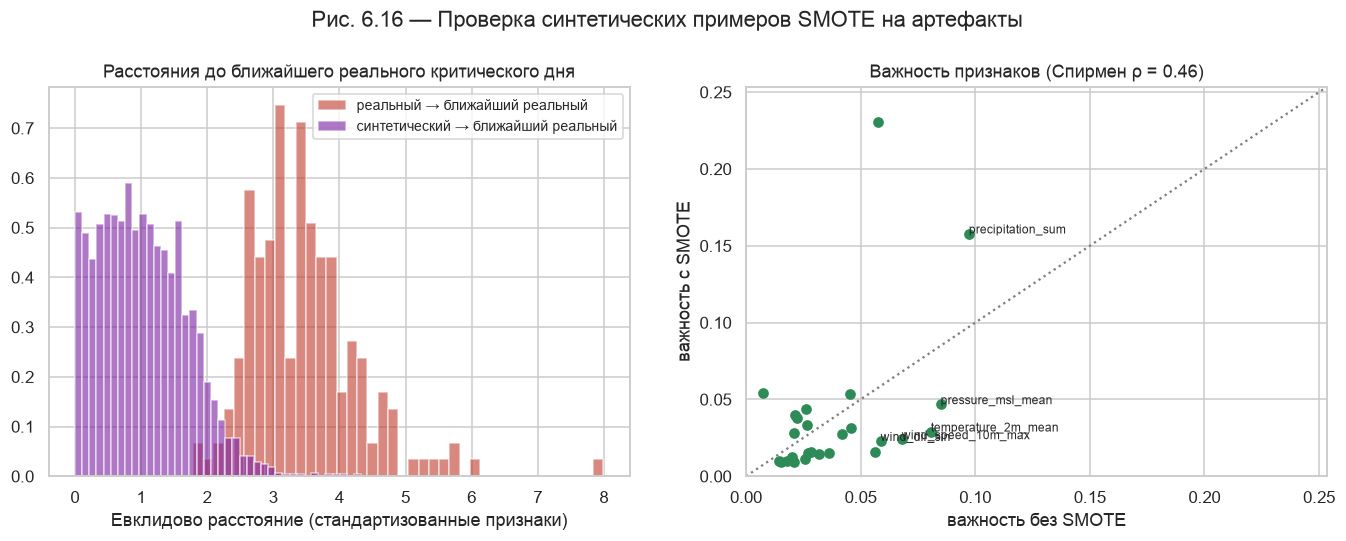

,Значение
Синтетических примеров,2536.000
Adversarial ROC-AUC (среднее по 5 фолдам),0.738
Adversarial ROC-AUC (std),0.047
Медиана расстояния: реальный → реальный,3.362
Медиана расстояния: синтетический → реальный,0.977
Спирмен ρ важностей признаков,0.456


In [19]:
scaler_c = StandardScaler().fit(X_tr)
Xs = scaler_c.transform(X_tr)
Xr, yr = SMOTE(random_state=SEED).fit_resample(Xs, yc_tr)
syn = Xr[len(Xs):]; real_min = Xs[yc_tr.values == 1]

adv_X = np.vstack([real_min, syn]); adv_y = np.r_[np.zeros(len(real_min)), np.ones(len(syn))]
adv_auc = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), adv_X, adv_y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
nn_real = NearestNeighbors(n_neighbors=2).fit(real_min)
d_real = nn_real.kneighbors(real_min)[0][:, 1]          # real -> nearest other real minority point
d_syn = nn_real.kneighbors(syn, n_neighbors=1)[0][:, 0]  # synthetic -> nearest real minority point
imp_no = pd.Series(m_no.named_steps["model"].feature_importances_, index=FEATURES)
imp_sm = pd.Series(m_sm.named_steps["model"].feature_importances_, index=FEATURES)
rho = imp_no.corr(imp_sm, method="spearman")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6))
a1.hist(d_real, bins=40, alpha=0.6, color="#C0392B", density=True, label="реальный → ближайший реальный")
a1.hist(d_syn, bins=40, alpha=0.6, color="#7B1FA2", density=True, label="синтетический → ближайший реальный")
a1.set(xlabel="Евклидово расстояние (стандартизованные признаки)", title="Расстояния до ближайшего реального критического дня"); a1.legend(fontsize=9)
a2.scatter(imp_no, imp_sm, color="#2E8B57")
for f in imp_no.sort_values().index[-5:]:
    a2.annotate(f, (imp_no[f], imp_sm[f]), fontsize=8)
lim = max(imp_no.max(), imp_sm.max()) * 1.1
a2.plot([0, lim], [0, lim], ":", color="gray"); a2.set(xlim=(0, lim), ylim=(0, lim), xlabel="важность без SMOTE",
                                                       ylabel="важность с SMOTE", title=f"Важность признаков (Спирмен ρ = {rho:.2f})")
fig.suptitle("Рис. 6.16 — Проверка синтетических примеров SMOTE на артефакты", y=1.03)
save("fig_6_16_smote_artifacts")
pd.Series({"Синтетических примеров": len(syn), "Adversarial ROC-AUC (среднее по 5 фолдам)": adv_auc.mean(),
           "Adversarial ROC-AUC (std)": adv_auc.std(),
           "Медиана расстояния: реальный → реальный": np.median(d_real), "Медиана расстояния: синтетический → реальный": np.median(d_syn),
           "Спирмен ρ важностей признаков": rho}, name="Значение").round(3).to_frame()

**Интерпретация.**
- **Adversarial ROC-AUC = 0.74** — классификатор заметно отличает синтетические критические дни от реальных. У синтетики есть «подпись», которую может выучить и основная модель.
- **Синтетические точки лежат гораздо ближе к реальным** (медианное расстояние 0.98), чем реальные критические дни друг к другу (3.36): SMOTE создаёт примеры на отрезках между соседями — более «типичные» и менее разнообразные, чем реальность. Модель видит сгущения вокруг известных случаев, но не новые варианты непогоды.
- **Важность признаков меняется существенно** (ρ Спирмена 0.46): с SMOTE модель опирается на другие признаки, чем без него, — синтетика меняет логику модели, а не только порог.
- Эти проверки показывают, что риск выучить артефакты **реален**. Принятые меры: тест всегда только на реальных данных; SMOTE только внутри пайплайна на обучающей выборке; умеренная доля синтетики и SMOTE на релевантном подмножестве признаков; в итоговой системе (ноутбук 04) для редкого класса используется `class_weight`, который не создаёт искусственных примеров.

## 4.5 Ответы на вопросы лабораторной (SMOTE)

**1. Сохраняет ли SMOTE на подмножестве признаков качество? Почему?** Да, и даже улучшает его, если подмножество выбрано по важности нелинейной модели: SMOTE на топ-10 признаках Random Forest дал Recall 0.56 и F1 0.34 против 0.35 и 0.30 на всех признаках. В пространстве без лишних признаков соседи осмысленнее, а интерполяция правдоподобнее. Плохо выбранное (SelectKBest) или слишком маленькое (топ-5) подмножество ухудшает результат.

**2. Влияет ли шум на эффективность SMOTE? Как?** Да: SMOTE интерполирует и между зашумлёнными примерами, «размножая» шум. Recall растёт, но растут и ложные тревоги, а PR-AUC падает (0.24 → 0.22). Поэтому порядок действий: сначала denoising, потом SMOTE.

**3. В каких сценариях SMOTE рекомендуется, а в каких нет?** *Рекомендуется:* сильный дисбаланс, при котором модель игнорирует редкий класс (у нас — 0 предсказанных критических дней); решение принимается при фиксированном пороге или в многоклассовой задаче, где один порог не настроить; редкий класс однороден; признаки отобраны. *Не рекомендуется:* когда нужны откалиброванные вероятности (SMOTE их искажает); когда порог можно выбрать на валидации (в бинарной задаче «дождь» SMOTE не дал выигрыша — ноутбук 03); когда редкий класс неоднороден (критическая погода = грозы + жара + мороз — интерполяция между ними даёт несуществующую погоду); при высокой размерности с шумными признаками; для валидационных и тестовых данных — никогда.

**4. Как проверить, что модель не учится на синтетических артефактах?** Оценивать только на реальных данных; проводить adversarial validation (у нас ROC-AUC 0.74 — тревожный сигнал); сравнивать расстояния синтетических и реальных примеров до ближайших реальных соседей; сравнивать важность признаков и калибровку с SMOTE и без него; сопоставлять с методами без синтетики (`class_weight`). Если синтетика отличима, долю SMOTE нужно уменьшить или заменить его перевзвешиванием.

---
# 5. Итог: принятые меры по снижению влияния (для отчёта)

| Фактор | Как обнаружен | Как смоделирован | Принятая мера и почему | Эффект |
|---|---|---|---|---|
| **Bias классов** | Recall 0.30 (дождь) против 0.97 (сухо) при пороге 0.5; accuracy маскирует проблему | удаление 30 % / 70 % дождливых дней | **порог решения выбран на валидации и применено перевзвешивание классов**, потому что они восстанавливают обнаружение редкого класса без искусственных данных | Recall дождя 0.30 → 0.76 (порог); при −70 %: F1 0.41 → 0.52 (reweighting) |
| **Bias на признаке** | падение ROC-AUC до 0.43 при искажённой облачности | облачность × 0.6 перед дождём | **исключение или перекалибровка признака по эталону**, потому что нормализация не исправляет связь признака с классом | ROC-AUC RF 0.43 → 0.79 |
| **Bias выборки / региона / измерений** | ноутбук 03 (D.1–D.3) | обучение только на лете, другие станции, недоучёт осадкомера | **контроль метрик по сезонам и регионам, сверка датчиков с соседними станциями** | раскалиброванный барометр обнаружен за 2 дня (ноутбук 04) |
| **Noise (гауссов)** | деградация всех моделей с ростом σ | шум σ = 0.2–1.0 | **выбрана устойчивая модель (Random Forest) и выполнен denoising EWMA при повышенном шуме датчика**, потому что EWMA уменьшает случайные колебания, сохраняя тренды | ROC-AUC +0.01…0.015, F1 +0.03 |
| **Noise (импульсный)** | выбросы ±6σ в 5 % показаний | сбои передачи | **выполнен denoising фильтром Хампеля**, потому что он заменяет только выбросы и не трогает нормальные значения | ошибка сигнала ÷5, F1 0.505 → 0.518 |
| **Underfitting** | низкое качество и на обучении, и на проверке (RF глубина 1–3, LR) | ограничение сложности | **выбрана нелинейная модель вместо линейной**, потому что LR упирается в предел 0.77 | ROC-AUC 0.77 → 0.79 |
| **Overfitting** | AUC обучения 1.0 при 0.66–0.77 на тесте | RF без ограничений, шум | **регуляризация Random Forest (глубина 12, лист ≥ 20), подобранная кросс-валидацией по времени**, потому что она сокращает разрыв, не вызывая недообучения | разрыв 0.23 → 0.10, тест 0.77 → 0.79 |
| **Дисбаланс (SMOTE)** | 0 предсказанных критических дней | — | **SMOTE только на обучающей выборке и на релевантных признаках; в итоговой системе — `class_weight`**, потому что синтетика отличима от реальных данных (adversarial AUC 0.74) | Recall критического класса 0 → 0.35 (0.56 на топ-10 признаках) |

**Общий вывод.** Несовершенство данных — дисбаланс, смещения, шум — не препятствие, а то, что нужно явно измерить, смоделировать и учесть. Для каждого фактора выбрана мера, проверенная на реальных тестовых данных, а не на искажённой выборке; там, где стандартный приём (нормализация против bias на признаке, фильтр на чистых данных, SMOTE для неоднородного класса) не работает, это показано и объяснено.